# Preprocessing U.S. tech job postings for salary prediction

## Objective and Value Proposition

The project aims to help job seekers establish salary expectations for comparable roles and identify skill categories associated with higher-paying opportunities. This project compares several salary prediction models, ranging from interpretable linear regression to more flexible machine learning models such as random forests and gradient boosting, to balance predictive accuracy with clear explanations of what drives salary. Using these models, job seekers can examine how different technical skills relate to salary, learn whether AI-related skills carry a salary premium beyond other technical skills in the current market, and understand whether higher-paying jobs require AI skills more often than lower-paying ones.

By incorporating regional economic information, we can also examine whether local conditions improve salary predictions and whether the association between skill requirements and advertised salary remains after accounting for these geographic differences. This could help students and early-career job seekers make more informed decisions about which skills to develop and where to look for work. Our conclusions will describe associations in job postings; they will not establish that acquiring a particular skill causes an increase in salary.

## Notebook scope

Each row represents a job posting. This notebook reads the raw Freehire extract, defines the salary sample, checks target quality and duplicates, prepares skill and location fields, and exports a documented set of columns.

Run the cells in order using a Python kernel with pandas 2 or later, NumPy, `us`, and `geonamescache`. Run from the repository root or the `notebooks` directory. The notebook uses helpers adapted from the original script in `scripts/salary_preprocessing.py` and reads the checked-in skill mapping.

In [1]:
from pathlib import Path
import ast
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if not (root / "scripts" / "salary_preprocessing.py").is_file():
    root = root.parent
if not (root / "scripts" / "salary_preprocessing.py").is_file():
    raise FileNotFoundError("Run from the repository root or the notebooks directory.")
sys.path.insert(0, str(root))

from scripts import salary_preprocessing as prep

archive_path = root / "data" / "freehire_tech.csv.zip"
mapping_path = root / "data" / "salary_skill_categories.txt"
output_path = root / "data" / "cleaned_job_postings.csv"
min_rows = 50_000
min_predictors = 10


from io import BytesIO
from IPython.display import Image
from matplotlib import pyplot as plt
from matplotlib import colors, patches, ticker

def show_figure(figure):
    image = BytesIO()
    figure.savefig(image, format="png", dpi=145, bbox_inches="tight", pad_inches=0.2)
    plt.close(figure)
    display(Image(data=image.getvalue()))

def salary_tick(value, _position):
    return f"${value / 1_000:,.0f}k"

## 1. Read the raw extract and define the sample

The archive contains the raw CSV. We keep postings whose country list is exactly `['us']`, then filter to postings dated in 2026 using UTC. This describes the available extract. The date coverage below shows the actual observation window.

In [2]:
raw = prep.load_data(archive_path)
row_counts = {"Raw postings": len(raw)}
original_columns = len(raw.columns)
print(f"Raw extract: {len(raw):,} rows × {original_columns} columns")

Raw extract: 876,684 rows × 27 columns


Raw extract: 876,684 rows × 27 columns


### Raw missingness by variable

This table covers all 27 columns and all rows in the raw archive, before the country, date, or salary filters. Missing values are nulls as read from the CSV, including blank cells. A recorded empty list (`[]`) is counted separately because the cell is present but lists no values. Every percentage uses the full raw row count as its denominator.

In [3]:
def show_column_missingness(frame):
    missing = frame.isna().sum()
    empty_lists = frame.select_dtypes(include=["object", "string"]).apply(
        lambda values: values.str.strip().eq("[]").sum()
    ).reindex(frame.columns, fill_value=0)
    missingness = pd.DataFrame({
        "Missing rows": missing,
        "Missing %": (missing / len(frame)).map("{:.2%}".format),
        "Empty-list rows": empty_lists,
        "Empty-list %": (empty_lists / len(frame)).map("{:.2%}".format),
    }).rename_axis("Variable").sort_values("Missing rows", ascending=False, kind="stable")
    with pd.option_context("display.max_rows", None):
        display(missingness)

show_column_missingness(raw)

,Missing rows,Missing %,Empty-list rows,Empty-list %
Variable,,,,
salary_max,738984,84.29%,0,0.00%
salary_period,736513,84.01%,0,0.00%
salary_min,735229,83.86%,0,0.00%
salary_currency,713291,81.36%,0,0.00%
company_hq_country,556825,63.51%,0,0.00%
work_mode,536332,61.18%,0,0.00%
employment_type,514968,58.74%,0,0.00%
seniority,510717,58.26%,0,0.00%
experience_years_min,352525,40.21%,0,0.00%


,Missing rows,Missing %,Empty-list rows,Empty-list %
Variable,,,,
salary_max,738984,84.29%,0,0.00%
salary_period,736513,84.01%,0,0.00%
salary_min,735229,83.86%,0,0.00%
salary_currency,713291,81.36%,0,0.00%
company_hq_country,556825,63.51%,0,0.00%
work_mode,536332,61.18%,0,0.00%
employment_type,514968,58.74%,0,0.00%
seniority,510717,58.26%,0,0.00%
experience_years_min,352525,40.21%,0,0.00%


In [4]:
us_jobs = prep.filter_us_jobs(raw)
row_counts["U.S. only"] = len(us_jobs)
jobs = prep.filter_2026_jobs(us_jobs)
row_counts["U.S. only, posted in 2026"] = len(jobs)

print(f"2026 posting dates (UTC): {jobs['posted_at'].min().date()} to {jobs['posted_at'].max().date()}")
display(pd.Series(row_counts, name="Rows").to_frame())
del raw, us_jobs

2026 posting dates (UTC): 2026-01-01 to 2026-08-07


,Rows
Raw postings,876684
U.S. only,364680
"U.S. only, posted in 2026",311210


2026 posting dates (UTC): 2026-01-01 to 2026-08-07


,Rows
Raw postings,876684
U.S. only,364680
"U.S. only, posted in 2026",311210


### Missingness after the U.S. and 2026 filters

This table covers all 27 columns after restricting to U.S.-only postings dated in 2026, before filtering on salary availability or currency. Percentages use the filtered row count, and recorded empty lists are counted separately from nulls.

In [5]:
print(f"U.S.-only, 2026 sample: {len(jobs):,} postings")
show_column_missingness(jobs)

U.S.-only, 2026 sample: 311,210 postings


,Missing rows,Missing %,Empty-list rows,Empty-list %
Variable,,,,
salary_period,226633,72.82%,0,0.00%
salary_max,223649,71.86%,0,0.00%
salary_min,223100,71.69%,0,0.00%
salary_currency,219256,70.45%,0,0.00%
work_mode,188878,60.69%,0,0.00%
seniority,187123,60.13%,0,0.00%
company_hq_country,162673,52.27%,0,0.00%
employment_type,149766,48.12%,0,0.00%
experience_years_min,101067,32.48%,0,0.00%


U.S.-only, 2026 sample: 311,210 postings


,Missing rows,Missing %,Empty-list rows,Empty-list %
Variable,,,,
salary_period,226633,72.82%,0,0.00%
salary_max,223649,71.86%,0,0.00%
salary_min,223100,71.69%,0,0.00%
salary_currency,219256,70.45%,0,0.00%
work_mode,188878,60.69%,0,0.00%
seniority,187123,60.13%,0,0.00%
company_hq_country,162673,52.27%,0,0.00%
employment_type,149766,48.12%,0,0.00%
experience_years_min,101067,32.48%,0,0.00%


## 2. Select yearly USD pay and construct the target

The analysis uses postings with salary originally reported as **yearly USD pay**. First, clean the salary fields and keep complete USD records. The pay-period heatmap below shows those records before selecting yearly pay. Then validate the yearly salary ranges and calculate the target directly as `(salary_min + salary_max) / 2`.

In [6]:
for column in ["salary_min", "salary_max"]:
    jobs[column] = pd.to_numeric(jobs[column], errors="coerce")
for column in ["salary_period", "salary_currency"]:
    jobs[column] = jobs[column].str.strip().replace("", pd.NA)
jobs["salary_period"] = jobs["salary_period"].str.lower()

display(jobs[prep.SALARY_COLS].isna().sum().rename("Missing values").to_frame())
salary_jobs = prep.filter_salary_usd(jobs)
row_counts["Complete USD salary fields"] = len(salary_jobs)
print(f"Salary sample coverage: {len(salary_jobs) / len(jobs):.1%} of U.S.-only 2026 postings")

Salary sample coverage: 26.6% of U.S.-only 2026 postings


,Missing values
salary_min,223100
salary_max,223649
salary_currency,219256
salary_period,226633


Salary sample coverage: 26.6% of U.S.-only 2026 postings


,Missing values
salary_min,223100
salary_max,223649
salary_currency,219256
salary_period,226633


### Missingness after filtering for complete USD salaries

This table uses postings with both salary endpoints, a pay period, and salary originally recorded in USD. It covers the 27 source columns before yearly-pay selection, salary validation, outlier screening, or deduplication. Empty lists are counted separately from nulls.

In [7]:
print(f"Complete USD salary sample: {len(salary_jobs):,} postings")
show_column_missingness(salary_jobs)

Complete USD salary sample: 82,679 postings


,Missing rows,Missing %,Empty-list rows,Empty-list %
Variable,,,,
work_mode,48552,58.72%,0,0.00%
seniority,43902,53.10%,0,0.00%
company_hq_country,41786,50.54%,0,0.00%
employment_type,39465,47.73%,0,0.00%
experience_years_min,18830,22.77%,0,0.00%
category,12677,15.33%,0,0.00%
company,1159,1.40%,0,0.00%
company_slug,1159,1.40%,0,0.00%
company_industries,1159,1.40%,32779,39.65%


Complete USD salary sample: 82,679 postings


,Missing rows,Missing %,Empty-list rows,Empty-list %
Variable,,,,
work_mode,48552,58.72%,0,0.00%
seniority,43902,53.10%,0,0.00%
company_hq_country,41786,50.54%,0,0.00%
employment_type,39465,47.73%,0,0.00%
experience_years_min,18830,22.77%,0,0.00%
category,12677,15.33%,0,0.00%
company,1159,1.40%,0,0.00%
company_slug,1159,1.40%,0,0.00%
company_industries,1159,1.40%,32779,39.65%


### Why the primary analysis uses yearly pay

The heatmap shows employment types within each recorded pay period among postings with complete USD salary fields, before restricting to yearly pay. Each cell shows the share and count of postings in that pay period. Postings with unlisted employment type stay in the denominator.

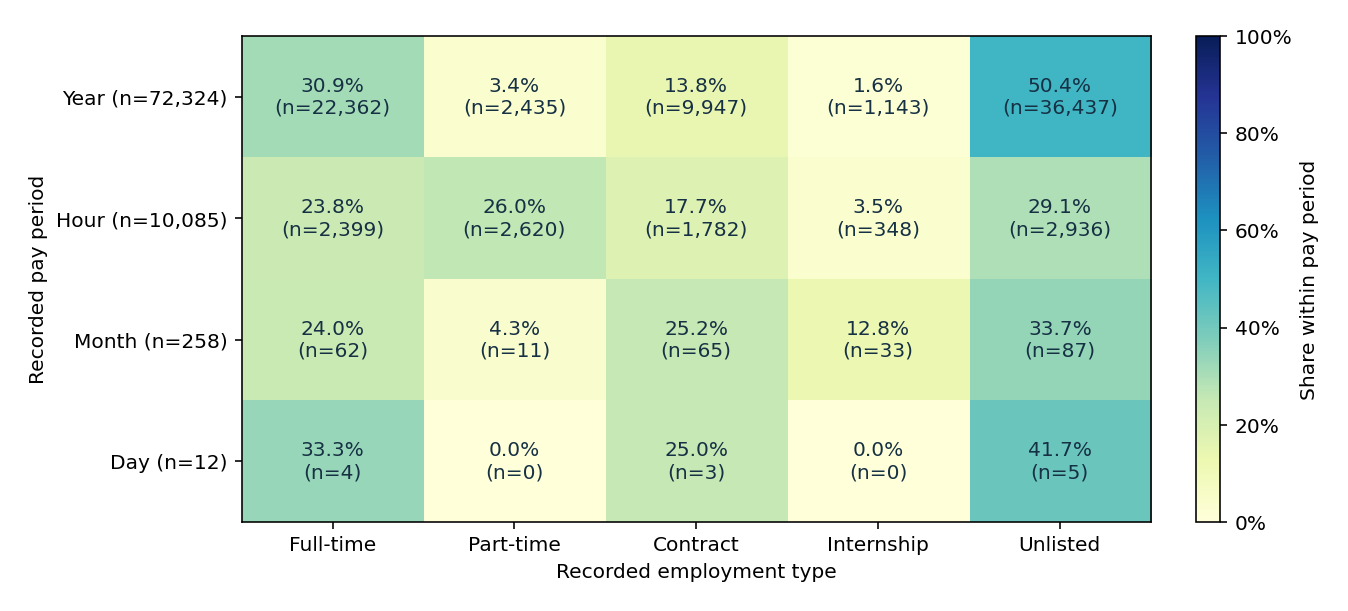

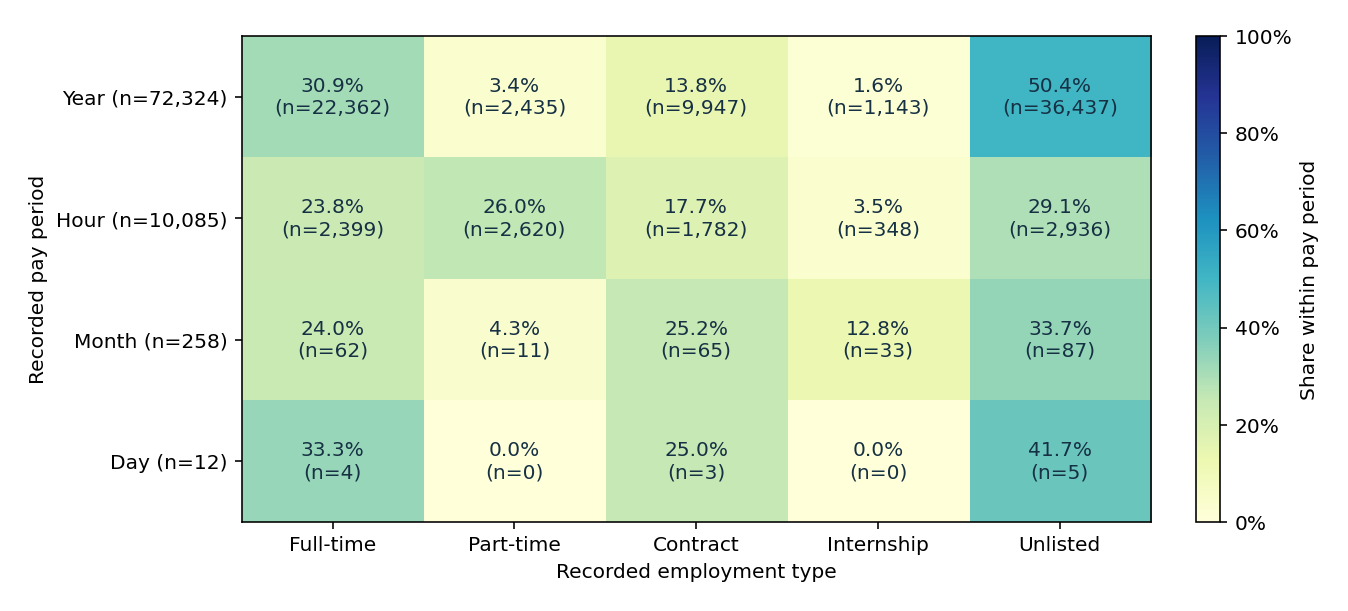

In [8]:
pay_order = ["year", "hour", "month", "day"]
employment_order = ["full_time", "part_time", "contract", "internship", "unlisted"]
employment_labels = ["Full-time", "Part-time", "Contract", "Internship", "Unlisted"]
employment_type = salary_jobs["employment_type"].fillna("unlisted")
pay_employment_counts = pd.crosstab(salary_jobs["salary_period"], employment_type).reindex(
    index=pay_order, columns=employment_order, fill_value=0
)
assert pay_employment_counts.to_numpy().sum() == len(salary_jobs)
pay_totals = pay_employment_counts.sum(axis=1)
pay_employment_share = pay_employment_counts.div(pay_totals, axis=0)

fig, ax = plt.subplots(figsize=(9, 3.9), layout="constrained")
image = ax.imshow(pay_employment_share, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(employment_labels)), employment_labels)
ax.set_yticks(range(len(pay_order)), [
    f"{period.title()} (n={pay_totals[period]:,})" for period in pay_order
])
ax.set(xlabel="Recorded employment type", ylabel="Recorded pay period")
for (row, col), share in np.ndenumerate(pay_employment_share.to_numpy()):
    count = pay_employment_counts.iat[row, col]
    ax.text(col, row, f"{share:.1%}\n(n={count:,})", ha="center", va="center",
            color="white" if share >= 0.62 else "#163044")
fig.colorbar(image, ax=ax, format=ticker.PercentFormatter(1), label="Share within pay period")
show_figure(fig)

**Finding.** Part-time labels are more common among hourly postings than among yearly postings, and many hourly postings omit employment type. Hourly pay alone does not tell us how much someone earns in a year because the hours worked can vary.

**Sample decision.** Keep postings with salary originally recorded in USD and `salary_period == "year"`. Their advertised yearly amounts can be compared directly. Yearly pay can still include part-time jobs and recording errors, so the salary-range checks follow separately.

In [9]:
yearly = salary_jobs.loc[salary_jobs["salary_period"].eq("year")].copy()
row_counts["Originally yearly USD pay"] = len(yearly)
print(f"Yearly USD postings: {len(yearly):,} of {len(salary_jobs):,} with complete USD salary fields.")

lower = yearly["salary_min"]
upper = yearly["salary_max"]
invalid_salary = pd.DataFrame({
    "Non-finite endpoint": ~(np.isfinite(lower) & np.isfinite(upper)),
    "Nonpositive endpoint": (lower <= 0) | (upper <= 0),
    "Reversed endpoints": lower > upper,
})
display(invalid_salary.sum().rename("Flagged yearly rows").to_frame())
yearly = yearly.loc[~invalid_salary.any(axis=1)].copy()
yearly["salary_mid_year"] = (yearly["salary_min"] + yearly["salary_max"]) / 2
row_counts["Valid yearly salary ranges"] = len(yearly)
del jobs, salary_jobs

Yearly USD postings: 72,324 of 82,679 with complete USD salary fields.


,Flagged yearly rows
Non-finite endpoint,0
Nonpositive endpoint,0
Reversed endpoints,0


Yearly USD postings: 72,324 of 82,679 with complete USD salary fields.


,Flagged yearly rows
Non-finite endpoint,0
Nonpositive endpoint,0
Reversed endpoints,0


### Distribution of yearly USD salaries before tail screening

The box plot shows validated salary midpoints for postings with pay originally reported per year in USD. The box spans the middle 50%, the line marks the median, and dots mark observations beyond the 1.5× IQR whiskers. The whiskers are calculated in dollars and displayed on a log scale. Both salary tails and repeated postings are included.

Yearly USD postings before tail screening: 72,324.
Median: $152,726 | 90th percentile: $228,246 | 99th percentile: $320,145.


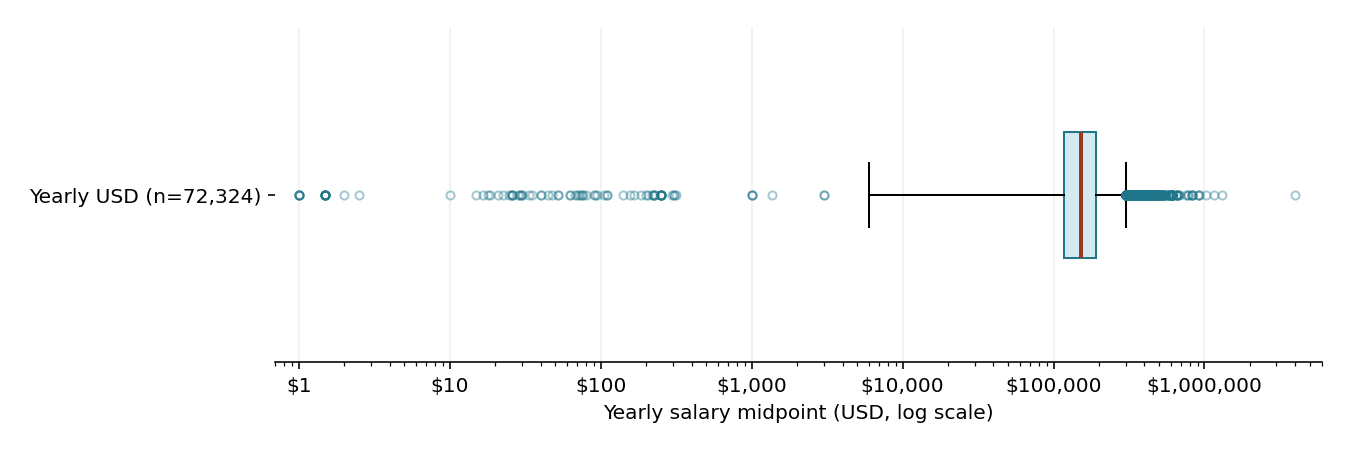

Yearly USD postings before tail screening: 72,324.
Median: $152,726 | 90th percentile: $228,246 | 99th percentile: $320,145.


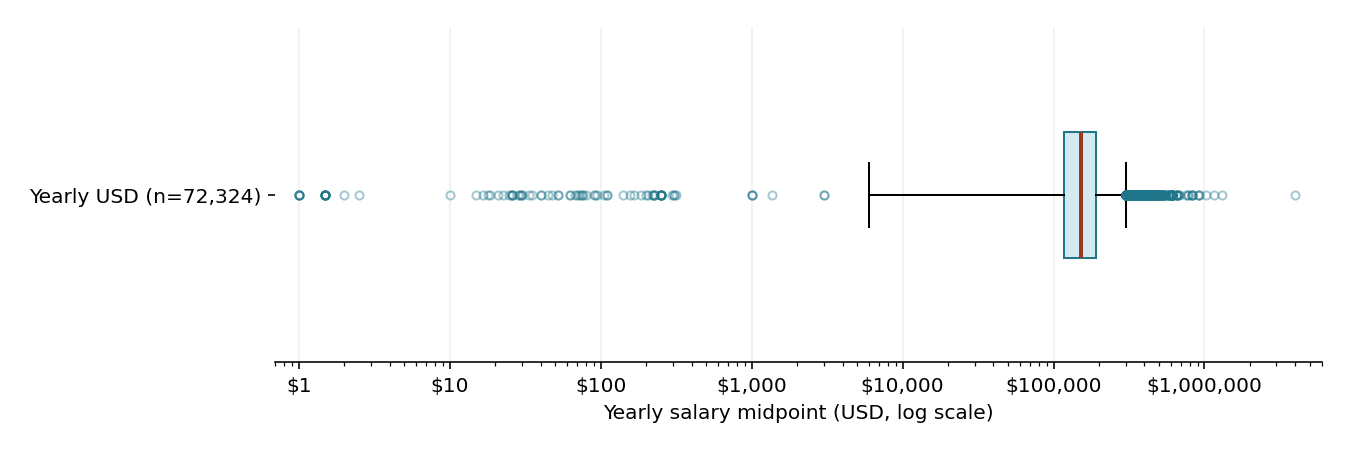

In [10]:
assert yearly["salary_period"].eq("year").all() and yearly["salary_currency"].eq("USD").all()
salary = yearly["salary_mid_year"]
print(f"Yearly USD postings before tail screening: {len(salary):,}.")
print(f"Median: ${salary.median():,.0f} | 90th percentile: ${salary.quantile(0.90):,.0f} | "
      f"99th percentile: ${salary.quantile(0.99):,.0f}.")
fig, ax = plt.subplots(figsize=(9, 2.8), layout="constrained")
ax.boxplot(salary, vert=False, widths=0.38, patch_artist=True,
           boxprops={"facecolor": "#d5eaf0", "edgecolor": "#20768a"},
           medianprops={"color": "#9a3a22", "linewidth": 2},
           flierprops={"markersize": 4, "markeredgecolor": "#20768a", "alpha": 0.4})
ax.set(xscale="log", xlabel="Yearly salary midpoint (USD, log scale)")
ax.set_yticks([1], [f"Yearly USD (n={len(salary):,})"])
ax.set_xticks([1, 10, 100, 1_000, 10_000, 100_000, 1_000_000])
ax.set_xlim(salary.min() * 0.7, salary.max() * 1.5)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
show_figure(fig)

**Finding.** The median is about $152,726, but reported midpoints span $1 to $4 million. The next subsection examines the tails before applying the salary screens.

### Screen the lower tail and inspect the upper tail of yearly pay

Keep postings originally reported as yearly USD pay for the cleaned dataset. Calculate both 1.5× IQR fences on the pre-screening yearly sample. Exclude midpoints strictly below the lower fence. This addresses unusually low values and can also remove genuine stipends or short appointments.

The upper fence defines the subset plotted below. This diagnostic shows the full upper tail before applying the percentile cutoff after deduplication. The histogram uses logarithmically spaced bins so the concentration near the fence and the sparse high end are both visible. The counts are before deduplication.

Yearly USD postings before screening: 72,324
Below the lower fence ($5,675): 85
Above the upper fence ($303,875): 1,102, before upper-tail trimming


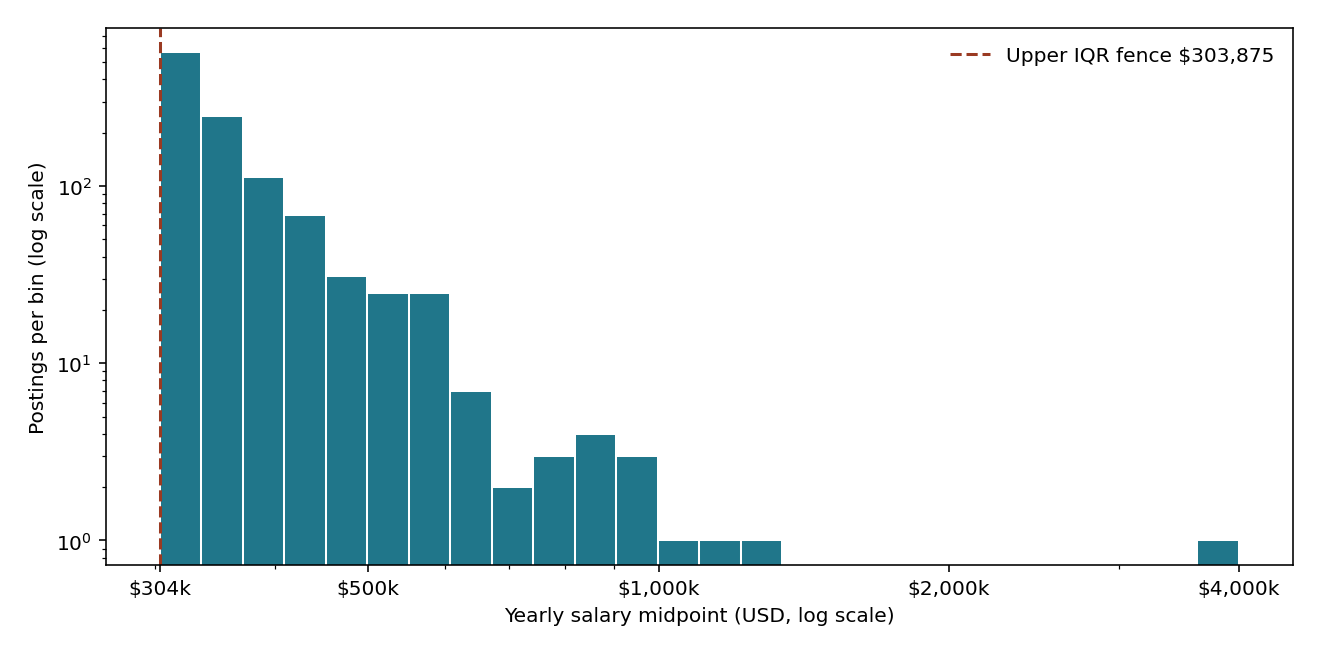

,salary_mid_year
count,1102.0
mean,368036.0
std,142267.0
min,303950.0
25%,314500.0
50%,333000.0
75%,372230.0
95%,525000.0
99%,772500.0
max,4000000.0


Yearly USD postings before screening: 72,324
Below the lower fence ($5,675): 85
Above the upper fence ($303,875): 1,102, before upper-tail trimming


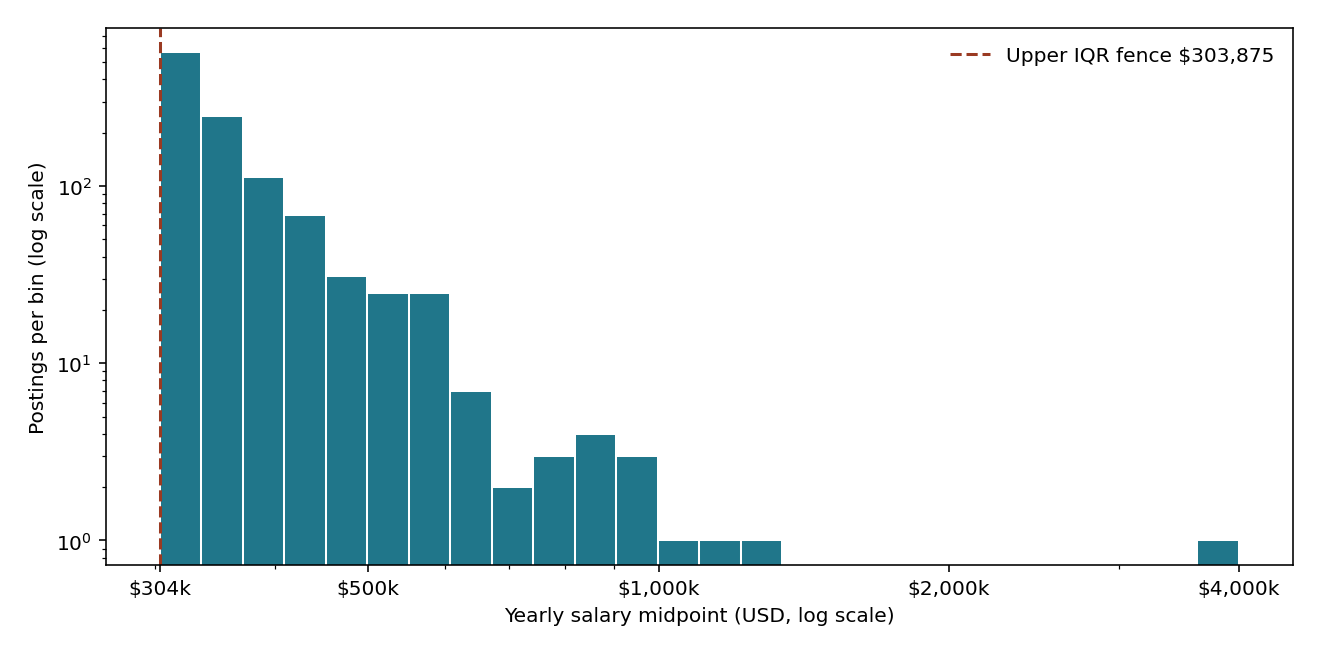

,salary_mid_year
count,1102.0
mean,368036.0
std,142267.0
min,303950.0
25%,314500.0
50%,333000.0
75%,372230.0
95%,525000.0
99%,772500.0
max,4000000.0


In [11]:
midpoint = yearly["salary_mid_year"]
yearly_q1, yearly_q3 = midpoint.quantile([0.25, 0.75])
yearly_iqr = yearly_q3 - yearly_q1
yearly_lower_fence = yearly_q1 - 1.5 * yearly_iqr
yearly_upper_fence = yearly_q3 + 1.5 * yearly_iqr
yearly_below_fence = midpoint.lt(yearly_lower_fence)
upper_tail = midpoint.loc[midpoint.gt(yearly_upper_fence)]

print(f"Yearly USD postings before screening: {len(yearly):,}")
print(f"Below the lower fence (${yearly_lower_fence:,.0f}): {yearly_below_fence.sum():,}")
print(f"Above the upper fence (${yearly_upper_fence:,.0f}): {len(upper_tail):,}, before upper-tail trimming")

if not upper_tail.empty:
    fig, ax = plt.subplots(figsize=(8.8, 4.2), layout="constrained")
    bins = np.geomspace(yearly_upper_fence, max(upper_tail.max(), yearly_upper_fence * 1.01), 27)
    ax.hist(upper_tail, bins=bins, color="#20768a", edgecolor="white")
    ax.axvline(yearly_upper_fence, color="#9a3a22", linestyle="--",
               label=f"Upper IQR fence ${yearly_upper_fence:,.0f}")
    ax.set(xscale="log", yscale="log", xlabel="Yearly salary midpoint (USD, log scale)",
           ylabel="Postings per bin (log scale)")
    ax.set_xticks([yearly_upper_fence, 500_000, 1_000_000, 2_000_000, upper_tail.max()])
    ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda value, _: f"${value / 1_000:,.0f}k"))
    ax.legend(frameon=False)
    show_figure(fig)
    display(upper_tail.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(0).to_frame())

clean = yearly.loc[~yearly_below_fence].copy()
row_counts["After lower salary screening"] = len(clean)
del yearly

**Finding.** Before deduplication, 1,102 yearly midpoints exceed the $303,875 upper fence. Four exceed $1 million, and the maximum is $4 million. The histogram retains the full range for review.

### Deduplicate postings before upper-tail screening

A URL can cover more than one location or posting. We collapse records only if all raw posting fields except the unique identifier and source agree. That rule also requires the same URL, timestamp, location, and original salary. Retained rows sharing a URL get a review flag that can also be used to keep a URL together across training and validation splits.

In [12]:
comparison_cols = [
    column for column in clean.columns
    if column not in {"public_slug", "source", "salary_mid_year"}
]
duplicate = clean.duplicated(subset=comparison_cols)
clean = clean.loc[~duplicate].copy()
clean["shared_posting_url"] = clean["url"].notna() & clean["url"].duplicated(keep=False)
row_counts["After deduplication"] = len(clean)
print(f"Equivalent rows removed: {duplicate.sum():,}")
print(f"Retained rows sharing a URL: {clean['shared_posting_url'].sum():,}")

Equivalent rows removed: 406
Retained rows sharing a URL: 230


Equivalent rows removed: 406
Retained rows sharing a URL: 230


### Remove salaries above the 99th percentile

After the lower IQR screen and deduplication, compute the 99th percentile of `salary_mid_year` across the full yearly USD sample. Exclude midpoints strictly above this cutoff and keep all ties at the cutoff. The percentage removed may differ slightly from 1% because of ties.

The cutoff is a reproducible scope decision. Some excluded salaries are supported by the original postings. The model and subsequent EDA describe the retained salary range, so they do not cover the highest-paying roles in the extract. The earlier histogram shows the full upper tail for comparison.

In [13]:
yearly_upper_cutoff = clean["salary_mid_year"].quantile(0.99)
above_yearly_cutoff = clean["salary_mid_year"].gt(yearly_upper_cutoff)
upper_trim_audit = clean.loc[above_yearly_cutoff, [
    "public_slug", "title", "salary_min", "salary_max", "salary_mid_year", "url"
]].copy()
print(f"99th-percentile cutoff: ${yearly_upper_cutoff:,.0f}")
print(f"Excluded above cutoff: {len(upper_trim_audit):,} of {len(clean):,} ({above_yearly_cutoff.mean():.2%})")
clean = clean.loc[~above_yearly_cutoff].copy()
row_counts["After upper salary screening"] = len(clean)
print(f"Retained yearly USD postings: {len(clean):,}")

99th-percentile cutoff: $320,145
Excluded above cutoff: 706 of 71,833 (0.98%)
Retained yearly USD postings: 71,127


99th-percentile cutoff: $320,145
Excluded above cutoff: 706 of 71,833 (0.98%)
Retained yearly USD postings: 71,127


## 3. Prepare geographic fields for a later join

The script can infer a state from a city name or a phrase in free text. We record that result as `state_candidate` for review. For the cost-of-living merge, use `state`, which accepts only a single explicit state token in the location and leaves multi-location strings unresolved. For postings identified as remote, we require that the location consist only of a remote label, an explicit state, and optionally a U.S. label. This makes the join conservative. A missing state does not remove the posting from the salary sample.

In [14]:
clean = prep.add_state_columns(clean).rename(columns={"state": "state_candidate"})
lookups = prep.build_location_lookups()
state_names = lookups["state_names"]
state_abbrs = lookups["state_abbrs"]
remote_pattern = lookups["remote_re"]
country_pattern = lookups["country_re"]

def explicit_state(location, remote):
    if not isinstance(location, str) or any(mark in location for mark in ";/|"):
        return None
    parts = prep.split_parts(location)
    candidates = {
        part if part in state_abbrs else state_names[part.lower()]
        for part in parts
        if part in state_abbrs or part.lower() in state_names
    }
    if len(candidates) != 1:
        return None
    if remote:
        qualifiers = [
            part for part in parts
            if part not in state_abbrs and part.lower() not in state_names
        ]
        if not any(remote_pattern.fullmatch(part) for part in qualifiers):
            return None
        if any(not (remote_pattern.fullmatch(part) or country_pattern.fullmatch(part))
               for part in qualifiers):
            return None
    return next(iter(candidates))

remote = (
    clean["work_mode"].eq("remote")
    | clean["location"].fillna("").map(lambda location: bool(remote_pattern.search(location)))
)
unique_inputs = pd.DataFrame({"location": clean["location"], "remote": remote}).drop_duplicates()
state_lookup = {
    (location, is_remote): explicit_state(location, is_remote)
    for location, is_remote in unique_inputs.itertuples(index=False, name=None)
    if isinstance(location, str)
}
clean["state"] = [state_lookup.get((location, is_remote)) for location, is_remote in zip(clean["location"], remote)]
clean["location_type"] = [
    "remote" if is_remote else prep.location_type(location, state, lookups)
    for location, state, is_remote in zip(clean["location"], clean["state"], remote)
]
print(f"Join-ready state coverage: {clean['state'].notna().sum():,} ({clean['state'].notna().mean():.1%})")
display(clean["location_type"].value_counts().rename("Rows").to_frame())

Join-ready state coverage: 44,587 (62.7%)


,Rows
location_type,
state,43859
remote,16210
untraditional,9468
us_only,1578
missing,12


Join-ready state coverage: 44,587 (62.7%)


,Rows
location_type,
state,43859
remote,16210
untraditional,9468
us_only,1578
missing,12


## 4. Prepare skill and company fields

We reuse the existing nine skill categories so group IDs stay consistent with the fixed mapping in `data/salary_skill_categories.txt`. Each indicator equals 1 when a posting mentions at least one skill in the group. `skills_listed` distinguishes an empty skills list from a populated list that matches no groups. The mapping is fixed for this notebook. If the skill mapping is re-estimated during model evaluation, fit it on training data only.

Company size and industry may list multiple values. We parse the lists and preserve the distinction between null and empty. For the baseline, we derive one company size band per posting from the largest reported band. Industry stays available for EDA and optional model experiments. Numeric experience retains its original missing values and valid zeros. Training-time imputation belongs in the model pipeline.

### Screen minimum required experience

Convert experience to numeric years. Treat negative, unparseable, or non-finite values as missing and preserve explicit zeros. The histogram shows the distribution before the experience cutoff.

Exclude postings that report **more than 15 years** of minimum experience. Fifteen is the 99th percentile among postings with reported experience before this screen, and the upper tail includes probable extraction errors. The rule can also exclude genuine requirements above 15 years. Keep postings reporting exactly 15 years or with missing experience.

In [15]:
reported_experience = pd.to_numeric(clean["experience_years_min"], errors="coerce")
invalid_experience = ~np.isfinite(reported_experience) | reported_experience.lt(0)
clean["experience_years_min"] = reported_experience.mask(invalid_experience)

experience = clean["experience_years_min"]
print(f"Experience missing after basic checks: {experience.isna().sum():,} of {len(clean):,} postings.")
max_experience_years = 15

Experience missing after basic checks: 12,808 of 71,127 postings.


Experience missing after basic checks: 12,808 of 71,127 postings.


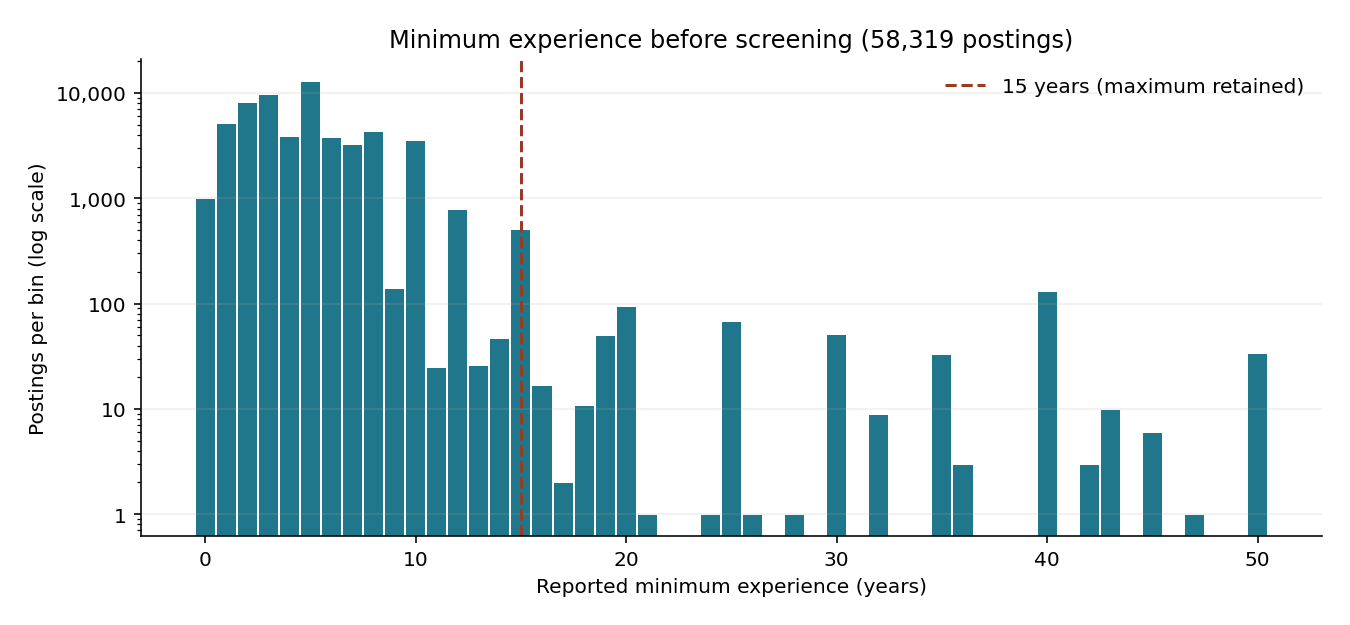

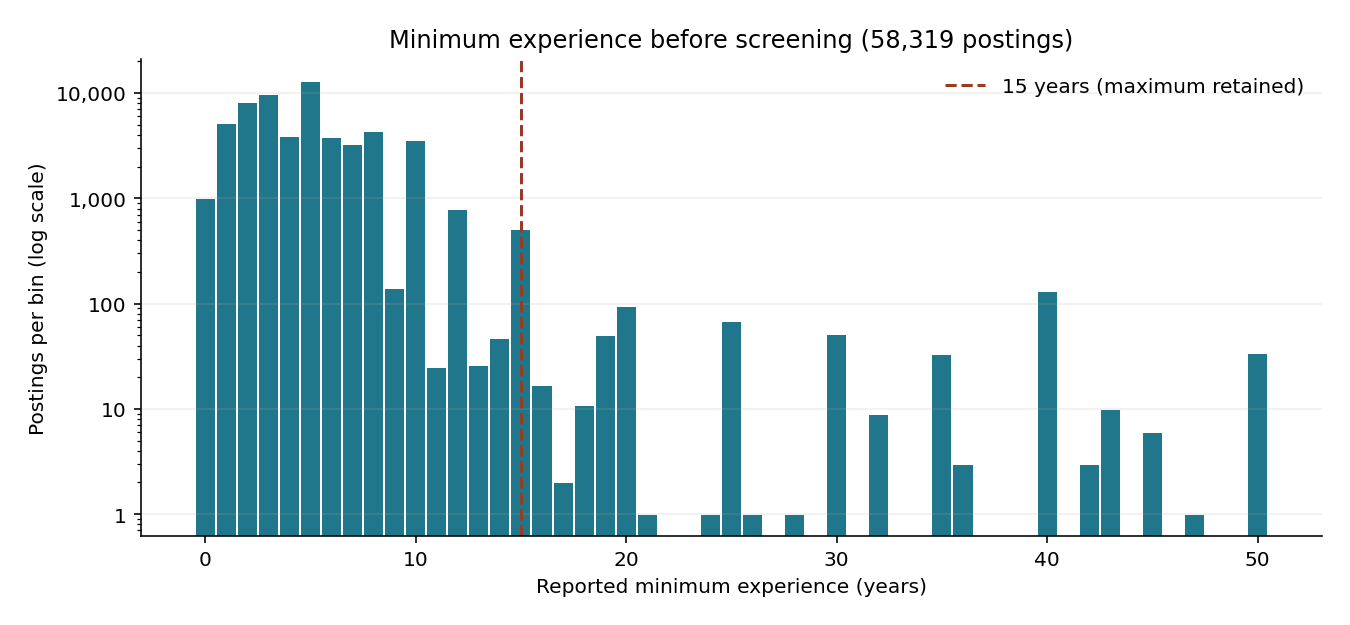

In [16]:
observed_years = experience.dropna()
year_bins = np.arange(-0.5, np.ceil(observed_years.max()) + 1.5, 1)
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.hist(observed_years, bins=year_bins, color="#20768a", edgecolor="white")
ax.axvline(max_experience_years, color="#9a3a22", linestyle="--", label="15 years (maximum retained)")
ax.set(title=f"Minimum experience before screening ({len(observed_years):,} postings)",
       xlabel="Reported minimum experience (years)", ylabel="Postings per bin (log scale)",
       yscale="log")
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

In [17]:
above_experience_cutoff = experience.gt(max_experience_years)
print(f"Postings excluded for experience above {max_experience_years}: {above_experience_cutoff.sum():,}")
clean = clean.loc[~above_experience_cutoff].copy()
row_counts["After experience screening"] = len(clean)
print(f"Postings retained: {len(clean):,}")

Postings excluded for experience above 15: 529
Postings retained: 70,598


Postings excluded for experience above 15: 529
Postings retained: 70,598


**Finding.** The cutoff excludes 529 postings, about 0.9% of the 58,319 with reported experience and 0.7% of all postings at this stage. The prior sample included 34 records reporting 50 years. The final sample keeps the 509 postings reporting exactly 15 years.

In [18]:
clusters = {}
for block in mapping_path.read_text(encoding="utf-8").strip().split("\n\n"):
    heading, *skills = block.splitlines()
    category_id = int(heading.split()[-1])
    if category_id in clusters or not skills:
        raise ValueError(f"Invalid skill group: {heading}")
    clusters[category_id] = skills
assert set(clusters) == set(range(prep.N_CATEGORIES))

clean = prep.add_cluster_dummies(prep.parse_skills_list(clean), clusters)
skill_cols = [f"skill_category_{i}" for i in range(prep.N_CATEGORIES)]
display(clean[skill_cols + ["skills_listed"]].agg(["sum", "mean"]).T.rename(
    columns={"sum": "Postings", "mean": "Share"}
).round(3))

for column in ["company_sizes", "company_industries"]:
    clean[column] = clean[column].map(ast.literal_eval, na_action="ignore")
    if not clean[column].dropna().map(lambda value: isinstance(value, list)).all():
        raise ValueError(f"{column} contains a non-list value.")

,Postings,Share
skill_category_0,30311.0,0.429
skill_category_1,40084.0,0.568
skill_category_2,32313.0,0.458
skill_category_3,32883.0,0.466
skill_category_4,24373.0,0.345
skill_category_5,19851.0,0.281
skill_category_6,21266.0,0.301
skill_category_7,23924.0,0.339
skill_category_8,22969.0,0.325
skills_listed,63639.0,0.901


,Postings,Share
skill_category_0,30311.0,0.429
skill_category_1,40084.0,0.568
skill_category_2,32313.0,0.458
skill_category_3,32883.0,0.466
skill_category_4,24373.0,0.345
skill_category_5,19851.0,0.281
skill_category_6,21266.0,0.301
skill_category_7,23924.0,0.339
skill_category_8,22969.0,0.325
skills_listed,63639.0,0.901


### Company size coverage

A blank cell means there is no recorded list. An empty list (`[]`) is present but contains no size band. Both count as unlisted in the variable profile. The table below shows them separately and uses all retained postings as the denominator.

In [19]:
company_sizes = clean["company_sizes"]
band_count = company_sizes.str.len()
size_status = pd.Series({
    "Blank or null": company_sizes.isna().sum(),
    "Empty list": band_count.eq(0).sum(),
    "One listed band": band_count.eq(1).sum(),
    "Multiple listed bands": band_count.gt(1).sum(),
}, name="Postings")
assert size_status.sum() == len(clean)
size_profile = size_status.to_frame()
size_profile["Share of postings"] = (size_profile["Postings"] / len(clean)).map("{:.1%}".format)
display(size_profile)

band_mentions = (
    company_sizes.explode()
    .dropna()
    .reset_index()
    .drop_duplicates()
)
band_frequency = band_mentions["company_sizes"].value_counts().rename("Postings").to_frame()
band_frequency["Share of postings"] = (band_frequency["Postings"] / len(clean)).map("{:.1%}".format)
display(band_frequency)

,Postings,Share of postings
Blank or null,687,1.0%
Empty list,784,1.1%
One listed band,49932,70.7%
Multiple listed bands,19195,27.2%


,Postings,Share of postings
company_sizes,,
1000+,51792,73.4%
501-1000,23815,33.7%
51-200,13173,18.7%
201-500,8450,12.0%
11-50,5474,7.8%
1-10,1344,1.9%


,Postings,Share of postings
Blank or null,687,1.0%
Empty list,784,1.1%
One listed band,49932,70.7%
Multiple listed bands,19195,27.2%


,Postings,Share of postings
company_sizes,,
1000+,51792,73.4%
501-1000,23815,33.7%
51-200,13173,18.7%
201-500,8450,12.0%
11-50,5474,7.8%
1-10,1344,1.9%


**Model preparation.** Use the largest listed band as the single company-size predictor. For example, `["11-50", "1000+"]` becomes `1000+`. The ordering follows headcount. The chosen band is the largest one reported, and the source does not establish the company's actual headcount. A blank or empty list becomes `Unlisted`. The original list stays available for review.

In [20]:
company_size_order = ["1-10", "11-50", "51-200", "201-500", "501-1000", "1000+"]
size_rank = {band: rank for rank, band in enumerate(company_size_order)}
clean["company_size_band"] = clean["company_sizes"].map(
    lambda bands: max(bands, key=size_rank.__getitem__) if isinstance(bands, list) and bands else "Unlisted"
)
selected_size_counts = clean["company_size_band"].value_counts().reindex(
    company_size_order + ["Unlisted"], fill_value=0
)
assert selected_size_counts.sum() == len(clean)
display(selected_size_counts.rename("Postings").to_frame())

,Postings
company_size_band,
1-10,338
11-50,1424
51-200,4823
201-500,3915
501-1000,6835
1000+,51792
Unlisted,1471


,Postings
company_size_band,
1-10,338
11-50,1424
51-200,4823
201-500,3915
501-1000,6835
1000+,51792
Unlisted,1471


### Clean and summarize optional categorical fields

Trim stray whitespace and treat blank labels as missing. Preserve missing values in the export and show them as **Unlisted** in these tables. For industries, trim and deduplicate tags within each posting, and count blank and empty lists together for the summary.

The tables report counts and shares of all cleaned postings. Job category and industry display the top ten observed values for readability, with the number of distinct observed values shown above each table. Industry shares can overlap because one posting can list several tags.

In [21]:
categorical_fields = ["category", "seniority", "employment_type", "work_mode"]
for column in categorical_fields:
    clean[column] = clean[column].str.strip().replace("", pd.NA)

clean["company_industries"] = clean["company_industries"].map(
    lambda tags: list(dict.fromkeys(tag.strip() for tag in tags if tag.strip())),
    na_action="ignore",
)

def show_composition(counts, unlisted, limit=None):
    shown = counts if limit is None else counts.head(limit)
    shown = pd.concat([shown, pd.Series({"Unlisted": unlisted})])
    composition = shown.rename("Postings").to_frame()
    composition["Share of cleaned postings"] = (shown / len(clean)).map("{:.1%}".format)
    display(composition.rename_axis("Value"))

for column in categorical_fields:
    counts = clean[column].value_counts()
    print(f"{column} ({len(counts):,} observed labels)")
    show_composition(counts, clean[column].isna().sum(), limit=10 if column == "category" else None)

industries = clean["company_industries"]
industry_counts = industries.explode().value_counts()
industry_unlisted = (industries.isna() | industries.str.len().eq(0)).sum()
print(f"company_industries ({len(industry_counts):,} observed tags)")
show_composition(industry_counts, industry_unlisted, limit=10)

category (32 observed labels)
seniority (8 observed labels)
employment_type (4 observed labels)
work_mode (3 observed labels)
company_industries (1,171 observed tags)


,Postings,Share of cleaned postings
Value,,
data_analytics,9161,13.0%
project_management,8413,11.9%
security,5443,7.7%
design,4599,6.5%
product,4553,6.4%
architecture,3457,4.9%
devops,2395,3.4%
qa,2371,3.4%
solutions_engineering,2129,3.0%


,Postings,Share of cleaned postings
Value,,
senior,21062,29.8%
staff,4268,6.0%
principal,4136,5.9%
lead,3779,5.4%
middle,1100,1.6%
c_level,844,1.2%
junior,761,1.1%
intern,476,0.7%
Unlisted,34172,48.4%


,Postings,Share of cleaned postings
Value,,
full_time,21928,31.1%
contract,9746,13.8%
part_time,2408,3.4%
internship,1114,1.6%
Unlisted,35402,50.1%


,Postings,Share of cleaned postings
Value,,
remote,16042,22.7%
hybrid,8636,12.2%
onsite,5684,8.1%
Unlisted,40236,57.0%


,Postings,Share of cleaned postings
Value,,
"Tech, Software & IT Services",9562,13.5%
Cloud Technologies,7662,10.9%
AI & ML,7014,9.9%
Data Management & Analytics,6615,9.4%
Emerging Technologies,5430,7.7%
Software Development & Engineering,5423,7.7%
Enterprise Software & Solutions,5297,7.5%
Cybersecurity,5045,7.1%
Manufacturing,4994,7.1%


... (2 outputs left out)

,Postings,Share of cleaned postings
Value,,
senior,21062,29.8%
staff,4268,6.0%
principal,4136,5.9%
lead,3779,5.4%
middle,1100,1.6%
c_level,844,1.2%
junior,761,1.1%
intern,476,0.7%
Unlisted,34172,48.4%


,Postings,Share of cleaned postings
Value,,
full_time,21928,31.1%
contract,9746,13.8%
part_time,2408,3.4%
internship,1114,1.6%
Unlisted,35402,50.1%


,Postings,Share of cleaned postings
Value,,
remote,16042,22.7%
hybrid,8636,12.2%
onsite,5684,8.1%
Unlisted,40236,57.0%


,Postings,Share of cleaned postings
Value,,
"Tech, Software & IT Services",9562,13.5%
Cloud Technologies,7662,10.9%
AI & ML,7014,9.9%
Data Management & Analytics,6615,9.4%
Emerging Technologies,5430,7.7%
Software Development & Engineering,5423,7.7%
Enterprise Software & Solutions,5297,7.5%
Cybersecurity,5045,7.1%
Manufacturing,4994,7.1%


### Join the state cost-of-living index

Use MERIC’s Q3 2026 overall `col_index` as the regional measure. It combines multiple spending categories and uses 100 as the U.S. benchmark. MERIC averages participating cities and metro areas within each state, so this describes state-level costs. Housing and the other component indexes remain available in the source file for more specific questions. [MERIC cost-of-living data](https://meric.mo.gov/data/cost-living-data-series)

Join the cleaned `state` to MERIC’s `state_code`. Keep every posting. An unresolved state or unmatched code leaves the index blank. The Q3 index is a single regional snapshot for descriptive comparisons across the posting sample.

In [22]:
meric_path = root / "data" / "MERIC_Cost_of_Living_2026_Q3.csv"
meric = pd.read_csv(meric_path, usecols=["state_code", "year", "quarter", "col_index"])
meric["state_code"] = meric["state_code"].str.strip().str.upper()
state_col = meric.loc[
    meric["year"].eq(2026) & meric["quarter"].eq(3) & meric["state_code"].isin(state_abbrs),
    ["state_code", "col_index"],
].rename(columns={"state_code": "state"})
state_col["col_index"] = pd.to_numeric(state_col["col_index"], errors="raise")
assert not state_col.empty and state_col["col_index"].notna().all()

posting_count = len(clean)
clean = clean.merge(state_col, on="state", how="left", validate="many_to_one", sort=False)
assert len(clean) == posting_count
assert clean.loc[clean["state"].isna(), "col_index"].isna().all()

join_counts = pd.Series({
    "Matched to MERIC": clean["col_index"].notna().sum(),
    "State unlisted": clean["state"].isna().sum(),
    "State listed with no MERIC match": (clean["state"].notna() & clean["col_index"].isna()).sum(),
}, name="Postings")
assert join_counts.sum() == posting_count
display(join_counts.to_frame().assign(Share=(join_counts / posting_count).map("{:.1%}".format)))

,Postings,Share
Matched to MERIC,44230,62.7%
State unlisted,26368,37.3%
State listed with no MERIC match,0,0.0%


,Postings,Share
Matched to MERIC,44230,62.7%
State unlisted,26368,37.3%
State listed with no MERIC match,0,0.0%


#### Distribution of the cost-of-living index

The state column gives each state and D.C. equal weight. The posting column counts the index once per matched posting, so states with more postings contribute more. Missing values are excluded from the summary statistics. An index of 116.4 indicates costs about 16.4% above the U.S. benchmark for the goods and services measured by MERIC.

In [23]:
matched_col = clean["col_index"].dropna()
col_summary = pd.DataFrame({
    "States and D.C.": state_col["col_index"].describe(),
    "Matched postings": matched_col.describe(),
}).rename(index={"count": "Count", "mean": "Mean", "std": "Std. dev.", "min": "Minimum",
                 "25%": "25th percentile", "50%": "Median", "75%": "75th percentile", "max": "Maximum"})
display(col_summary.round(2))
print(f"Share of matched postings above the U.S. benchmark (100): {matched_col.gt(100).mean():.1%}.")

Share of matched postings above the U.S. benchmark (100): 67.1%.


,States and D.C.,Matched postings
Count,51.00,44230.00
Mean,103.42,117.11
Std. dev.,18.77,20.12
Minimum,83.80,83.80
25th percentile,91.05,97.80
Median,97.00,116.40
75th percentile,111.55,137.90
Maximum,186.00,186.00


Share of matched postings above the U.S. benchmark (100): 67.1%.


,States and D.C.,Matched postings
Count,51.00,44230.00
Mean,103.42,117.11
Std. dev.,18.77,20.12
Minimum,83.80,83.80
25th percentile,91.05,97.80
Median,97.00,116.40
75th percentile,111.55,137.90
Maximum,186.00,186.00


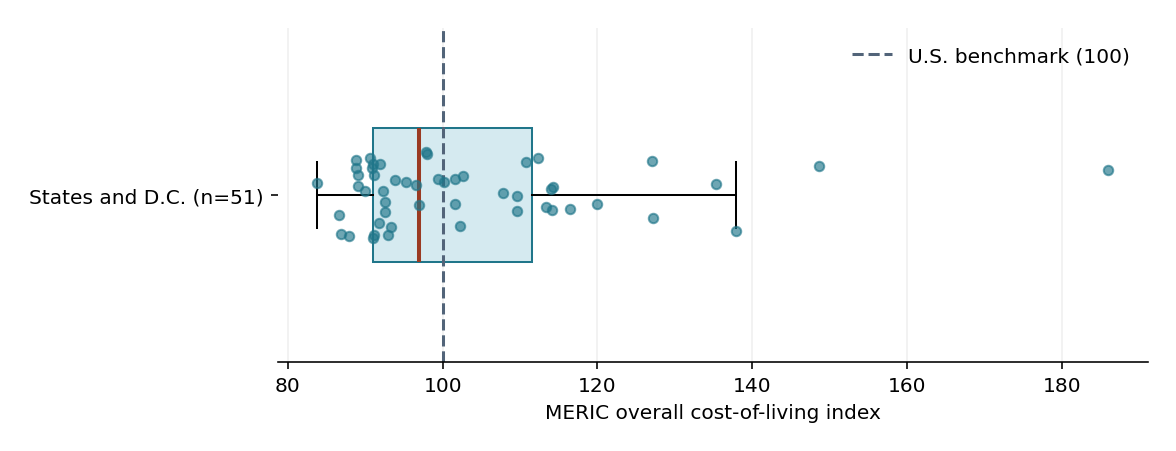

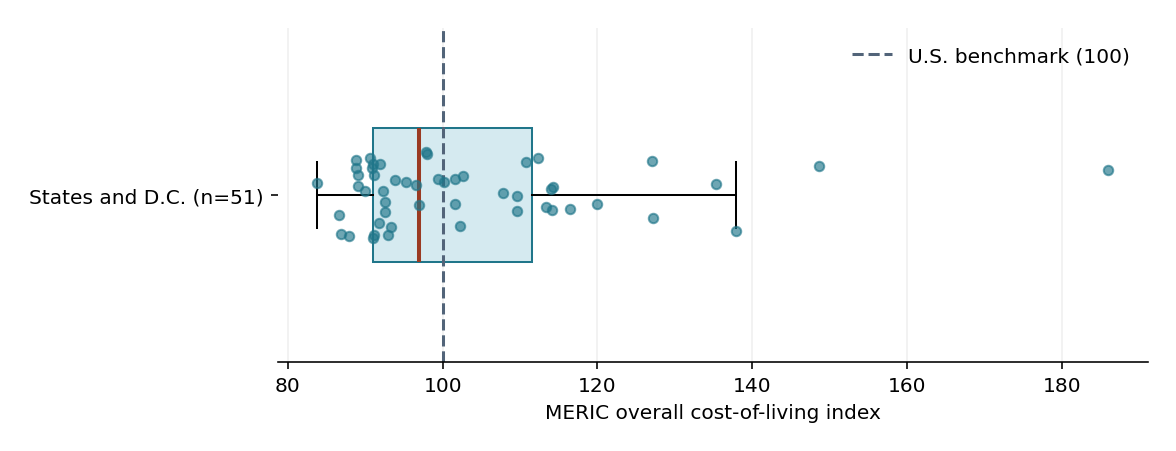

In [24]:
state_index = state_col["col_index"]
fig, ax = plt.subplots(figsize=(7.8, 2.8), layout="constrained")
ax.boxplot(state_index, vert=False, widths=0.28, patch_artist=True, showfliers=False,
           boxprops={"facecolor": "#d5eaf0", "edgecolor": "#20768a"},
           medianprops={"color": "#9a3a22", "linewidth": 2})
jitter = np.random.default_rng(0).uniform(-0.09, 0.09, size=len(state_index))
ax.scatter(state_index, 1 + jitter, s=22, color="#20768a", alpha=0.65, zorder=3)
ax.axvline(100, color="#526479", linestyle="--", label="U.S. benchmark (100)")
ax.set_yticks([1], [f"States and D.C. (n={len(state_index):,})"])
ax.set(xlabel="MERIC overall cost-of-living index", ylim=(0.65, 1.35))
ax.grid(axis="x", alpha=0.2)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
show_figure(fig)

**Finding.** The median matched posting has an index of 116.4, compared with a median below 100 when states and D.C. get equal weight. The index ranges from 83.8 in Oklahoma to 186.0 in Hawaii. About two-thirds of matched postings are in states above the U.S. benchmark. This describes the locations represented in the matched sample.

## 5. Select and document the final columns

The export includes the salary target, predictors, optional EDA fields, and geographic features. Source salary components, raw location text, the inferred state candidate, and the original skill and company-size lists remain in the preprocessing data for review.

### Missing-data decision and baseline treatment

> **Missing-data decision.** Exclude `work_mode`, `seniority`, `employment_type`, and `company_industries` from the baseline because more than 40% of their values are missing or unlisted. Keep these fields in the cleaned CSV so we can document coverage without guessing what postings did not report.
>
> **Baseline treatment.** Preserve nulls in the cleaned CSV. At modeling time, fill missing experience with the training-set median and add a missingness flag. For company size, one-hot encode the largest reported band, with an explicit Unlisted category. The nine skill indicators and `skills_listed` are complete.

In [25]:
target = "salary_mid_year"
baseline = skill_cols + ["skills_listed", "experience_years_min", "company_size_band"]
optional = ["category", "seniority", "employment_type", "company_industries", "work_mode"]
geography = ["state", "location_type", "col_index"]
final_columns = [target] + baseline + optional + geography
final = clean.loc[:, final_columns].reset_index(drop=True)
list_cols = ["company_industries"]
row_counts["Final cleaned dataset"] = len(final)
display(pd.Series(row_counts, name="Rows").to_frame())

,Rows
Raw postings,876684
U.S. only,364680
"U.S. only, posted in 2026",311210
Complete USD salary fields,82679
Originally yearly USD pay,72324
Valid yearly salary ranges,72324
After lower salary screening,72239
After deduplication,71833
After upper salary screening,71127
After experience screening,70598


,Rows
Raw postings,876684
U.S. only,364680
"U.S. only, posted in 2026",311210
Complete USD salary fields,82679
Originally yearly USD pay,72324
Valid yearly salary ranges,72324
After lower salary screening,72239
After deduplication,71833
After upper salary screening,71127
After experience screening,70598


In [26]:
definitions = {
    "salary_mid_year": "Midpoint of the advertised USD salary range",
    "skills_listed": "Whether the posting lists at least one skill",
    "experience_years_min": "Minimum stated experience in years",
    "company_size_band": "Largest reported company headcount band",
    "category": "One job-function label",
    "seniority": "Job seniority label",
    "employment_type": "Employment arrangement, such as full-time or contract",
    "company_industries": "One or more industry tags",
    "work_mode": "Reported onsite, hybrid, or remote work arrangement",
    "state": "Explicit state code used for the MERIC join",
    "col_index": "MERIC Q3 2026 overall cost of living (U.S. = 100)",
    "location_type": "Location classification, including remote or unresolved",
}
roles = {
    "Target": [target],
    "Baseline": baseline,
    "Optional EDA": optional,
    "Geography": geography,
}
profile = []
for role, columns in roles.items():
    for column in columns:
        values = final[column]
        unavailable = values.isna()
        if column == "company_size_band":
            unavailable |= values.eq("Unlisted")
        if column in list_cols:
            unavailable |= values.str.len().eq(0)
        meaning = definitions.get(column, "Posting mentions a skill from this group")
        profile.append({
            "Column": column,
            "Role": role,
            "Meaning": meaning,
            "Type": "List" if column in list_cols else str(values.dtype),
            "Missing or unlisted": int(unavailable.sum()),
            "Share": f"{unavailable.mean():.1%}",
        })
display(pd.DataFrame(profile).set_index("Column"))

,Role,Meaning,Type,Missing or unlisted,Share
Column,,,,,
salary_mid_year,Target,Midpoint of the advertised USD salary range,float64,0,0.0%
skill_category_0,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_1,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_2,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_3,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_4,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_5,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_6,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_7,Baseline,Posting mentions a skill from this group,int64,0,0.0%


,Role,Meaning,Type,Missing or unlisted,Share
Column,,,,,
salary_mid_year,Target,Midpoint of the advertised USD salary range,float64,0,0.0%
skill_category_0,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_1,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_2,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_3,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_4,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_5,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_6,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_7,Baseline,Posting mentions a skill from this group,int64,0,0.0%


## 6. Validate and export

The checks enforce the project's minimum of 50,000 postings and 10 predictors. The CSV stores list fields as JSON arrays. Read those cells with `json.loads` after loading the CSV, skipping nulls. Empty lists are exported as `[]`. The export includes the MERIC overall cost-of-living index. Missing state matches are exported as blanks.

In [27]:
assert len(final) >= min_rows, f"Only {len(final):,} rows after cleaning."
assert len(baseline) >= min_predictors and len(set(baseline)) == len(baseline)
assert final.columns.is_unique and clean["public_slug"].is_unique
assert final["experience_years_min"].dropna().le(max_experience_years).all()
assert final["company_size_band"].isin(company_size_order + ["Unlisted"]).all()
assert clean["salary_period"].eq("year").all()
assert clean["salary_currency"].eq("USD").all()
assert np.isfinite(final[target]).all()
assert final[target].between(yearly_lower_fence, yearly_upper_cutoff).all()
assert final[skill_cols + ["skills_listed"]].isin([0, 1]).all().all()
assert not final.loc[final["skills_listed"].eq(0), skill_cols].any().any()

export = final.copy()
for column in list_cols:
    export[column] = export[column].map(json.dumps, na_action="ignore")
temporary_path = output_path.with_suffix(".csv.tmp")
export.to_csv(temporary_path, index=False)
temporary_path.replace(output_path)

reloaded = pd.read_csv(output_path)
assert reloaded.shape == final.shape and reloaded.columns.tolist() == final_columns
for column in list_cols:
    restored = reloaded[column].map(json.loads, na_action="ignore")
    assert restored.isna().equals(final[column].isna())
    present = restored.notna()
    assert restored[present].equals(final.loc[present, column])

print(f"Exported {len(final):,} postings and {len(final_columns)} columns to {output_path.relative_to(root)}.")
print(f"Baseline: {len(baseline)} named predictors before encoding.")

Exported 70,598 postings and 21 columns to data/cleaned_job_postings.csv.
Baseline: 12 named predictors before encoding.


Exported 70,598 postings and 21 columns to data/cleaned_job_postings.csv.
Baseline: 12 named predictors before encoding.


### Preview of the cleaned dataset

The first five rows show the salary target and all baseline predictors. The transposed view below shows every retained field for the first three postings, including the geography columns. These previews use the final dataset that is exported to CSV.

In [28]:
print(f"Cleaned dataset: {len(final):,} postings × {final.shape[1]} columns")
display(final[[target] + baseline].head(5))
display(final.head(3).T.rename(columns=lambda index: f"Posting {index + 1}"))

Cleaned dataset: 70,598 postings × 21 columns


,salary_mid_year,skill_category_0,skill_category_1,skill_category_2,skill_category_3,skill_category_4,skill_category_5,skill_category_6,skill_category_7,skill_category_8,skills_listed,experience_years_min,company_size_band
0,174100.0,1,1,0,1,1,1,1,0,1,1,2.0,1000+
1,174100.0,1,1,0,1,1,1,1,0,1,1,2.0,1000+
2,135030.0,1,1,0,1,1,1,1,0,1,1,4.0,1000+
3,135030.0,1,1,0,1,1,1,1,0,1,1,4.0,1000+
4,107500.0,0,1,0,0,0,0,0,1,0,1,2.0,11-50


,Posting 1,Posting 2,Posting 3
salary_mid_year,174100.0,174100.0,135030.0
skill_category_0,1,1,1
skill_category_1,1,1,1
skill_category_2,0,0,0
skill_category_3,1,1,1
skill_category_4,1,1,1
skill_category_5,1,1,1
skill_category_6,1,1,1
skill_category_7,0,0,0
skill_category_8,1,1,1


Cleaned dataset: 70,598 postings × 21 columns


,salary_mid_year,skill_category_0,skill_category_1,skill_category_2,skill_category_3,skill_category_4,skill_category_5,skill_category_6,skill_category_7,skill_category_8,skills_listed,experience_years_min,company_size_band
0,174100.0,1,1,0,1,1,1,1,0,1,1,2.0,1000+
1,174100.0,1,1,0,1,1,1,1,0,1,1,2.0,1000+
2,135030.0,1,1,0,1,1,1,1,0,1,1,4.0,1000+
3,135030.0,1,1,0,1,1,1,1,0,1,1,4.0,1000+
4,107500.0,0,1,0,0,0,0,0,1,0,1,2.0,11-50


,Posting 1,Posting 2,Posting 3
salary_mid_year,174100.0,174100.0,135030.0
skill_category_0,1,1,1
skill_category_1,1,1,1
skill_category_2,0,0,0
skill_category_3,1,1,1
skill_category_4,1,1,1
skill_category_5,1,1,1
skill_category_6,1,1,1
skill_category_7,0,0,0
skill_category_8,1,1,1


## 7. Explore salary, geography, and skill groups

These plots use the cleaned U.S. postings with pay originally reported in yearly USD. The charts describe this salary-disclosing sample. The analysis uses the cleaned values before training-time imputation or encoding. To regenerate the figures, use a Python kernel with Matplotlib installed.

### Cost of living and advertised yearly salaries

The correlation table compares two views. The posting-level comparison uses each matched posting's salary, so states with more postings carry more weight. The state-level comparison uses one median salary per state or D.C. with at least 30 postings. Pearson measures linear association, while Spearman measures how consistently the two variables move together in rank.

,Observations,Pearson,Spearman
Comparison,,,
Matched postings,44230,0.292,0.288
State medians (at least 30 postings),47,0.389,0.436


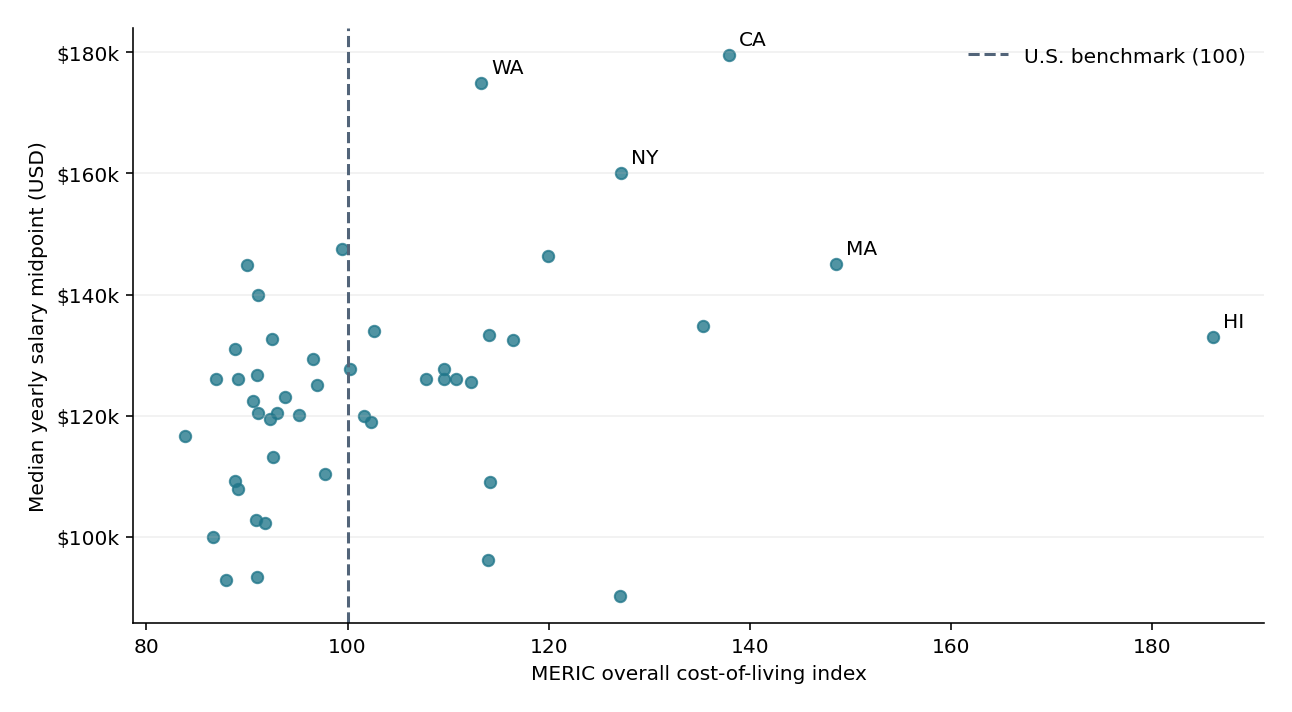

,Observations,Pearson,Spearman
Comparison,,,
Matched postings,44230,0.292,0.288
State medians (at least 30 postings),47,0.389,0.436


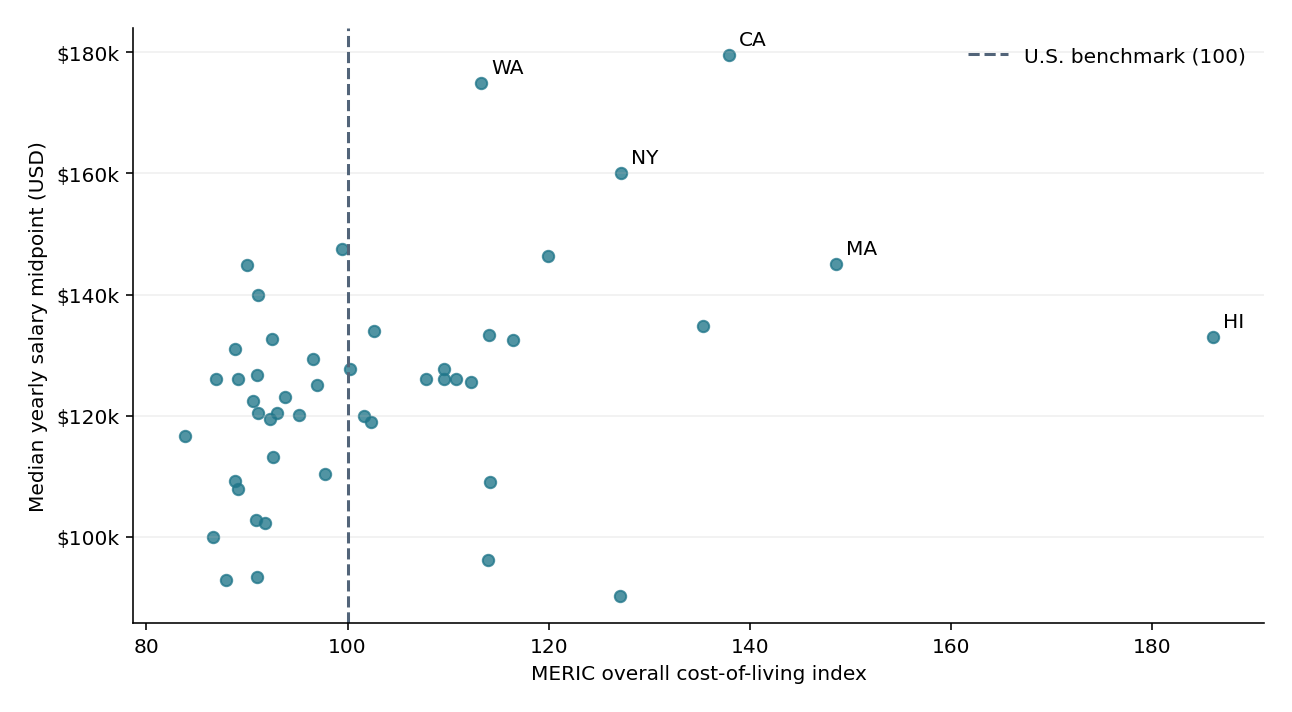

In [29]:
matched_salary = final.loc[final["col_index"].notna(), ["state", "col_index", target]]
salary_groups = matched_salary.groupby("state")[target]
state_salary = salary_groups.agg(postings="size", mean="mean", median="median")
state_salary["p25"] = salary_groups.quantile(0.25)
state_salary["p75"] = salary_groups.quantile(0.75)
state_salary = state_salary.join(state_col.set_index("state")["col_index"])
min_state_postings = 30
state_comparison = state_salary.loc[state_salary["postings"].ge(min_state_postings)]

correlations = []
for label, frame, salary_column in [
    ("Matched postings", matched_salary, target),
    ("State medians (at least 30 postings)", state_comparison, "median"),
]:
    index_values, salary_values = frame["col_index"], frame[salary_column]
    correlations.append({
        "Comparison": label,
        "Observations": len(frame),
        "Pearson": index_values.corr(salary_values),
        "Spearman": index_values.rank().corr(salary_values.rank()),
    })
display(pd.DataFrame(correlations).set_index("Comparison").round(3))

fig, ax = plt.subplots(figsize=(8.6, 4.6), layout="constrained")
ax.scatter(state_comparison["col_index"], state_comparison["median"],
           s=32, color="#20768a", alpha=0.78)
for code in ["CA", "WA", "NY", "MA", "HI"]:
    if code in state_comparison.index:
        row = state_comparison.loc[code]
        ax.annotate(code, (row["col_index"], row["median"]), xytext=(5, 5),
                    textcoords="offset points")
ax.axvline(100, color="#526479", linestyle="--", label="U.S. benchmark (100)")
ax.set(xlabel="MERIC overall cost-of-living index", ylabel="Median yearly salary midpoint (USD)")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(salary_tick))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
show_figure(fig)

**Finding.** Higher cost of living tends to accompany higher advertised salary. Pearson correlation is about **0.29** across the 44,230 matched postings and **0.39** across 47 state-level medians. Hawaii has the highest index (186.0) and a median of about $133,000, while California has an index of 137.9 and a median of about $180,000. The association is descriptive and may reflect differences in which jobs are advertised in each state.

### State tile map of cost of living and salary

The 3×3 legend combines cost of living (left to right) and median yearly salary (bottom to top). The low, middle, and high bands are based on thirds of the eligible state-level values. Gray tiles have fewer than 30 matched postings. The companion table shows the original index, counts, and salary summaries.

Cost-of-living band boundaries: 91.97 and 109.00.
Median salary band boundaries: $120,027 and $128,783.


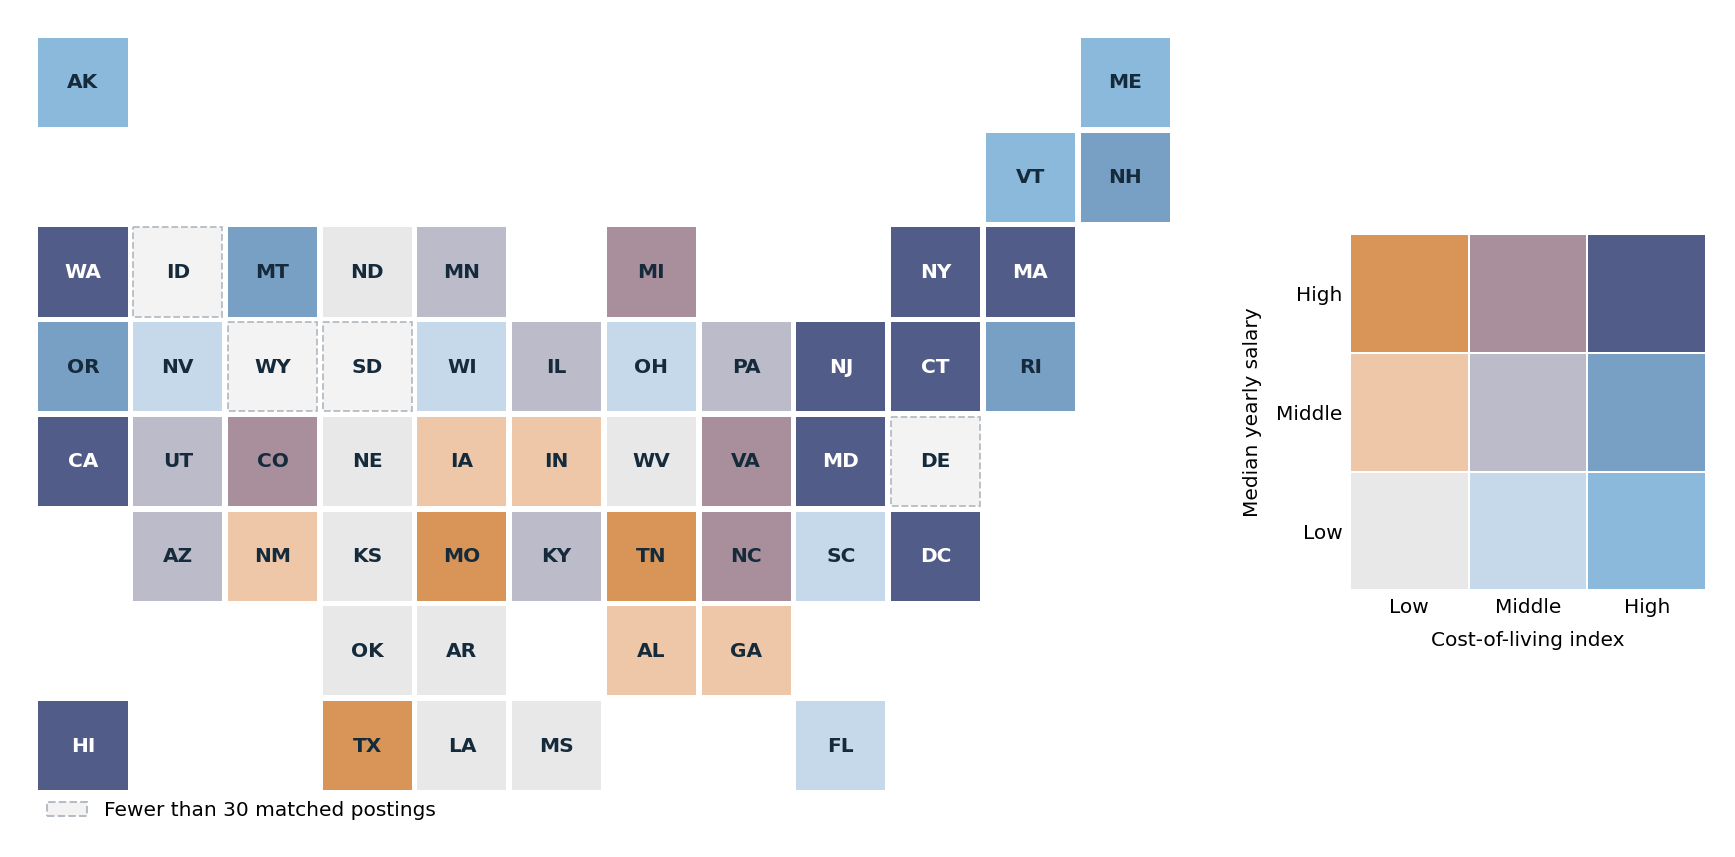

,postings,col_index,mean,p25,median,p75
state,,,,,,
CA,12195,137.9,180515.0,142900.0,179525.0,215500.0
WA,2566,113.3,171238.0,143000.0,174950.0,205038.0
NY,4470,127.2,159456.0,115172.0,160000.0,198538.0
VA,3288,99.4,153250.0,118650.0,147500.0,183500.0
MD,1733,119.9,149009.0,117500.0,146300.0,180000.0
MA,2760,148.6,146526.0,115000.0,145000.0,172500.0
TN,346,90.0,136586.0,100375.0,144800.0,167100.0
DE,18,101.6,146334.0,112500.0,144082.0,167800.0
TX,2276,91.1,144397.0,105000.0,140000.0,177500.0


Cost-of-living band boundaries: 91.97 and 109.00.
Median salary band boundaries: $120,027 and $128,783.


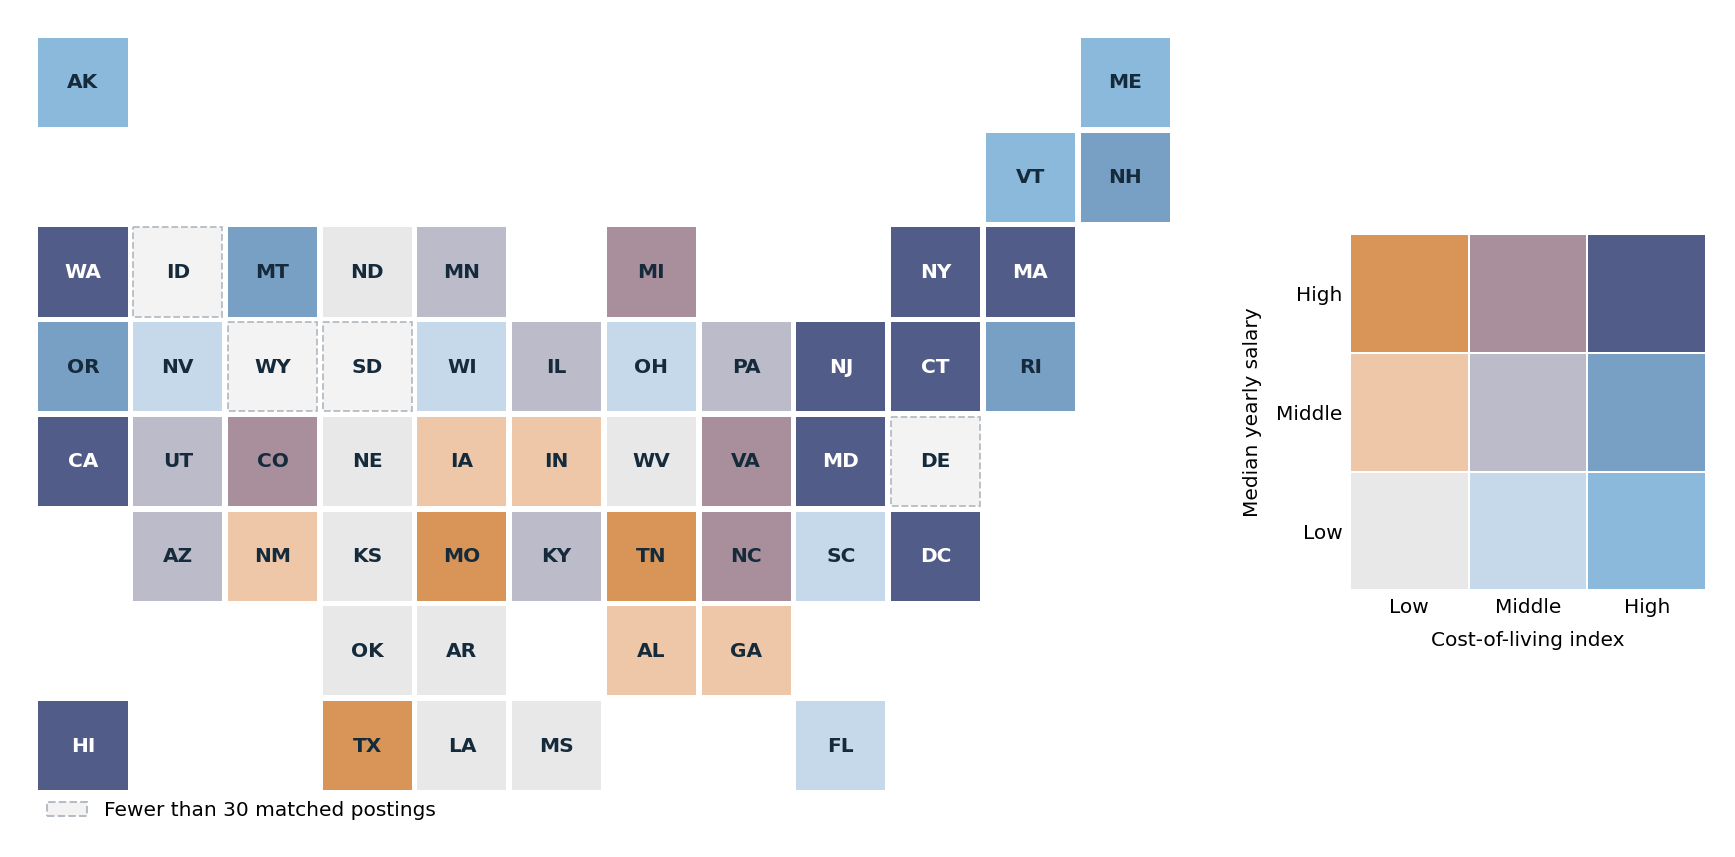

,postings,col_index,mean,p25,median,p75
state,,,,,,
CA,12195,137.9,180515.0,142900.0,179525.0,215500.0
WA,2566,113.3,171238.0,143000.0,174950.0,205038.0
NY,4470,127.2,159456.0,115172.0,160000.0,198538.0
VA,3288,99.4,153250.0,118650.0,147500.0,183500.0
MD,1733,119.9,149009.0,117500.0,146300.0,180000.0
MA,2760,148.6,146526.0,115000.0,145000.0,172500.0
TN,346,90.0,136586.0,100375.0,144800.0,167100.0
DE,18,101.6,146334.0,112500.0,144082.0,167800.0
TX,2276,91.1,144397.0,105000.0,140000.0,177500.0


In [30]:
state_grid = [
    "AK -- -- -- -- -- -- -- -- -- -- ME",
    "-- -- -- -- -- -- -- -- -- -- VT NH",
    "WA ID MT ND MN -- MI -- -- NY MA --",
    "OR NV WY SD WI IL OH PA NJ CT RI --",
    "CA UT CO NE IA IN WV VA MD DE -- --",
    "-- AZ NM KS MO KY TN NC SC DC -- --",
    "-- -- -- OK AR -- AL GA -- -- -- --",
    "HI -- -- TX LA MS -- -- FL -- -- --",
]
tiles = [(row, col, code) for row, line in enumerate(state_grid)
         for col, code in enumerate(line.split()) if code != "--"]
tile_codes = [code for _, _, code in tiles]
assert len(tile_codes) == len(set(tile_codes)) == 51
assert set(tile_codes) == state_abbrs

col_edges = state_comparison["col_index"].quantile([1 / 3, 2 / 3]).to_numpy()
salary_edges = state_comparison["median"].quantile([1 / 3, 2 / 3]).to_numpy()
col_band = np.searchsorted(col_edges, state_comparison["col_index"], side="left")
salary_band = np.searchsorted(salary_edges, state_comparison["median"], side="left")
tile_bands = dict(zip(state_comparison.index, zip(salary_band, col_band)))
# Rows are salary bands and columns are cost-of-living bands, both low to high.
palette = [
    ["#e8e8e8", "#c5d9ea", "#8ab9db"],
    ["#edc7a7", "#bcbbca", "#789fc4"],
    ["#d99557", "#a98e9c", "#525c89"],
]
small_sample_fill = "#f3f3f3"

fig, (ax, legend_ax) = plt.subplots(
    1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [3.5, 1]}, layout="constrained"
)
for row, col, code in tiles:
    band = tile_bands.get(code)
    fill = small_sample_fill if band is None else palette[band[0]][band[1]]
    ax.add_patch(patches.Rectangle((col, row), 0.94, 0.94, facecolor=fill,
                                   edgecolor="#b5bcc3" if band is None else "none",
                                   linestyle="--", linewidth=0.9))
    ink = "white" if band == (2, 2) else "#152b3b"
    ax.text(col + 0.47, row + 0.47, code, ha="center", va="center", color=ink, fontweight="bold")
ax.set(xlim=(-0.1, 12), ylim=(8, -0.1), aspect="equal")
ax.axis("off")
ax.legend(handles=[patches.Patch(facecolor=small_sample_fill, edgecolor="#b5bcc3",
                                  linestyle="--", label=f"Fewer than {min_state_postings} matched postings")],
          loc="lower left", bbox_to_anchor=(0, -0.055), frameon=False)

for salary_level, row_colors in enumerate(palette):
    for col_level, shade in enumerate(row_colors):
        legend_ax.add_patch(patches.Rectangle(
            (col_level, salary_level), 1, 1, facecolor=shade, edgecolor="white"
        ))
legend_ax.set(xlim=(0, 3), ylim=(0, 3), aspect="equal")
legend_ax.set_xticks([0.5, 1.5, 2.5], ["Low", "Middle", "High"])
legend_ax.set_yticks([0.5, 1.5, 2.5], ["Low", "Middle", "High"])
legend_ax.set_xlabel("Cost-of-living index", labelpad=7)
legend_ax.set_ylabel("Median yearly salary", labelpad=7)
legend_ax.tick_params(length=0)
legend_ax.spines[:].set_visible(False)
show_figure(fig)

print(f"Cost-of-living band boundaries: {col_edges[0]:.2f} and {col_edges[1]:.2f}.")
print(f"Median salary band boundaries: ${salary_edges[0]:,.0f} and ${salary_edges[1]:,.0f}.")
display(state_salary[["postings", "col_index", "mean", "p25", "median", "p75"]]
        .sort_values("median", ascending=False)
        .round({"mean": 0, "p25": 0, "median": 0, "p75": 0}))


**Coverage.** The map shows all 50 states and D.C. Colors combine both measures for the 47 areas with at least 30 matched postings. The table gives the exact values and shows how much salaries vary within each state.

### Most frequently listed skills

The word cloud shows the top 30 recorded skill tags. Larger words appear in more postings. The ranked bar chart below shows exact counts for the top 15. Each posting counts once per tag, and shares use the cleaned yearly-pay postings that list at least one skill.

Postings with listed skills: 63,639 of 70,598.


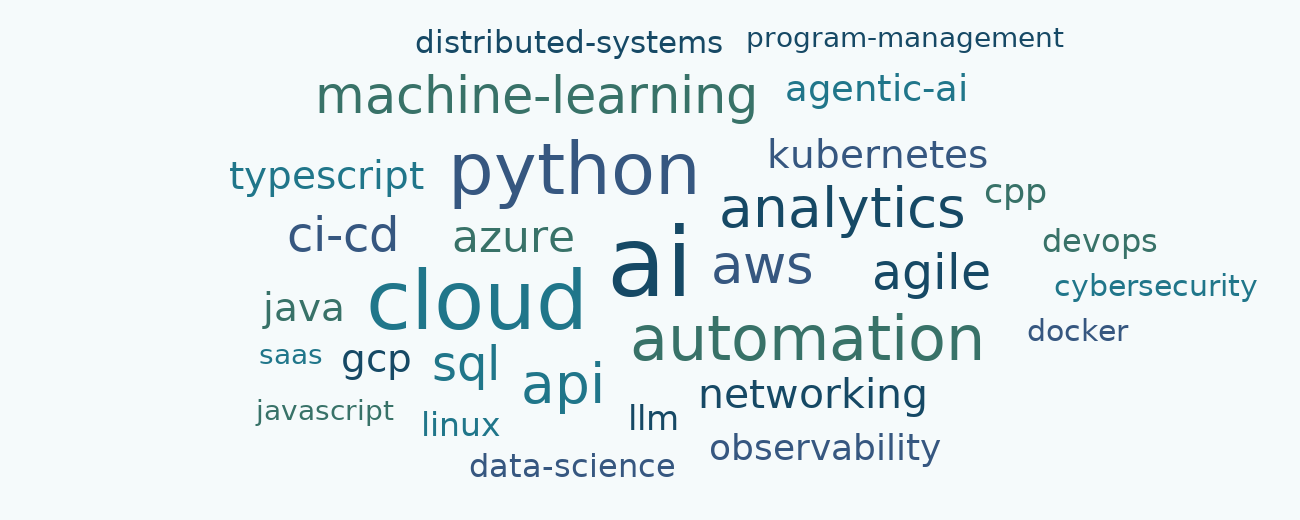

Postings with listed skills: 63,639 of 70,598.


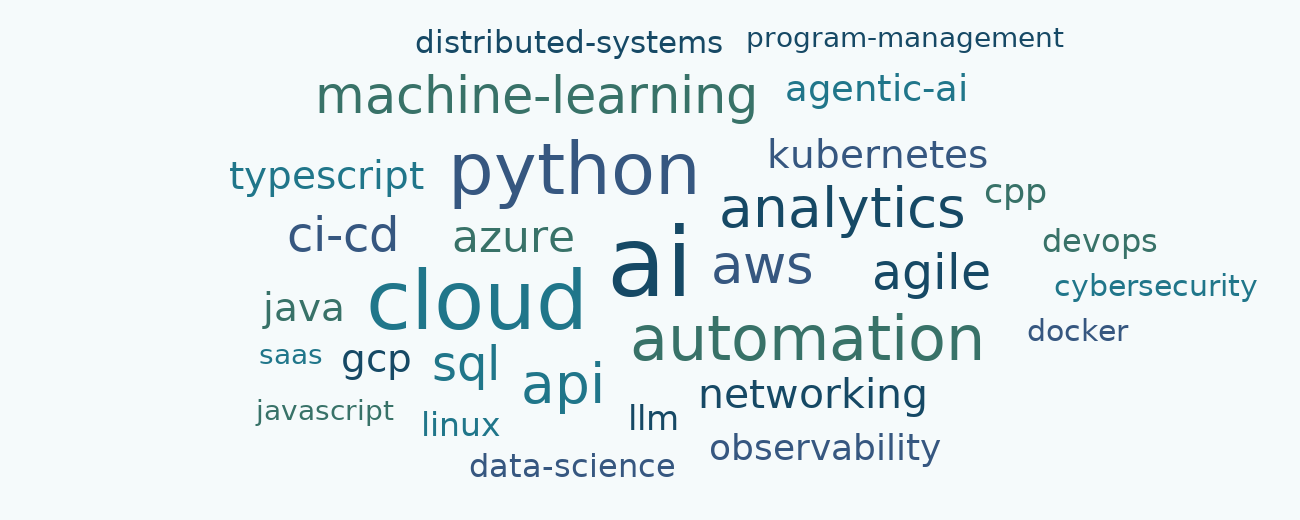

In [31]:
skill_postings = final.loc[final["skills_listed"].eq(1)]
print(f"Postings with listed skills: {len(skill_postings):,} of {len(final):,}.")
tag_counts = (
    clean.loc[clean["skills_listed"].eq(1), "skills_list"].map(lambda tags: list(dict.fromkeys(tags)))
    .explode().value_counts()
)

from matplotlib import font_manager
from PIL import Image as PillowImage, ImageDraw, ImageFont

cloud_counts = tag_counts.head(30)
width, height = 1300, 520
cloud = PillowImage.new("RGB", (width, height), "#f5fafb")
draw = ImageDraw.Draw(cloud)
font_path = font_manager.findfont("DejaVu Sans")
palette = ["#164965", "#20768a", "#365780", "#387268"]
occupied = []
angles = np.linspace(0, 34 * np.pi, 2700)

for index, (tag, count) in enumerate(cloud_counts.items()):
    size = round(96 * (count / cloud_counts.iloc[0]) ** 0.65)
    font = ImageFont.truetype(font_path, size)
    left, top, right, bottom = draw.textbbox((0, 0), tag, font=font)
    word_width, word_height = right - left, bottom - top
    for angle in angles:
        x = round(width / 2 + 9 * angle * np.cos(angle) - word_width / 2)
        y = round(height / 2 + 4 * angle * np.sin(angle) - word_height / 2)
        box = (x - 9, y - 7, x + word_width + 9, y + word_height + 7)
        if box[0] < 20 or box[1] < 20 or box[2] > width - 20 or box[3] > height - 20:
            continue
        if any(box[0] < r and box[2] > l and box[1] < b and box[3] > t
               for l, t, r, b in occupied):
            continue
        draw.text((x - left, y - top), tag, font=font, fill=palette[index % len(palette)])
        occupied.append(box)
        break
assert len(occupied) == len(cloud_counts), "Some skill tags did not fit in the word cloud."
cloud_image = BytesIO()
cloud.save(cloud_image, format="PNG")
display(Image(data=cloud_image.getvalue()))

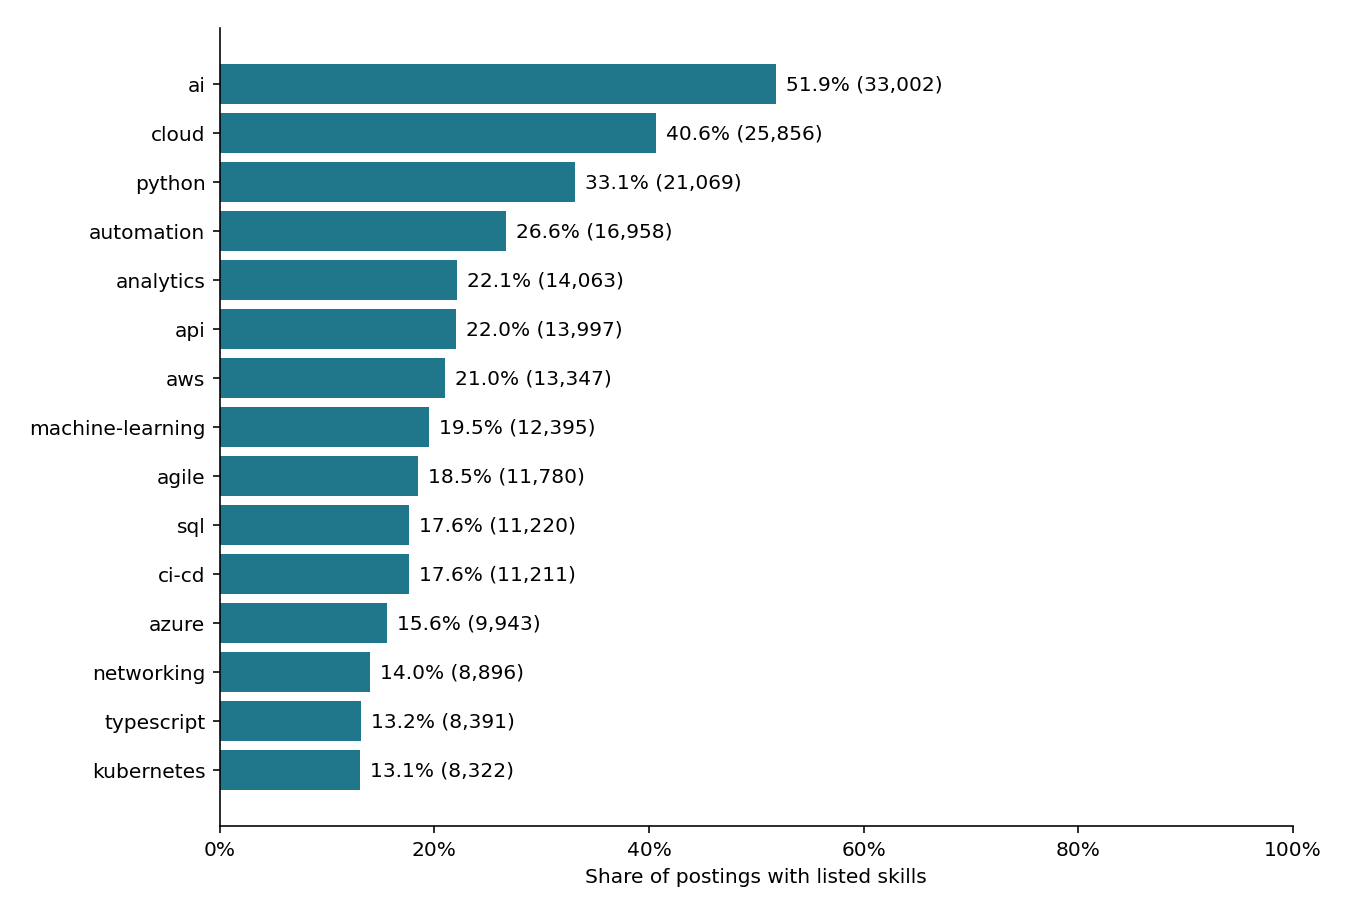

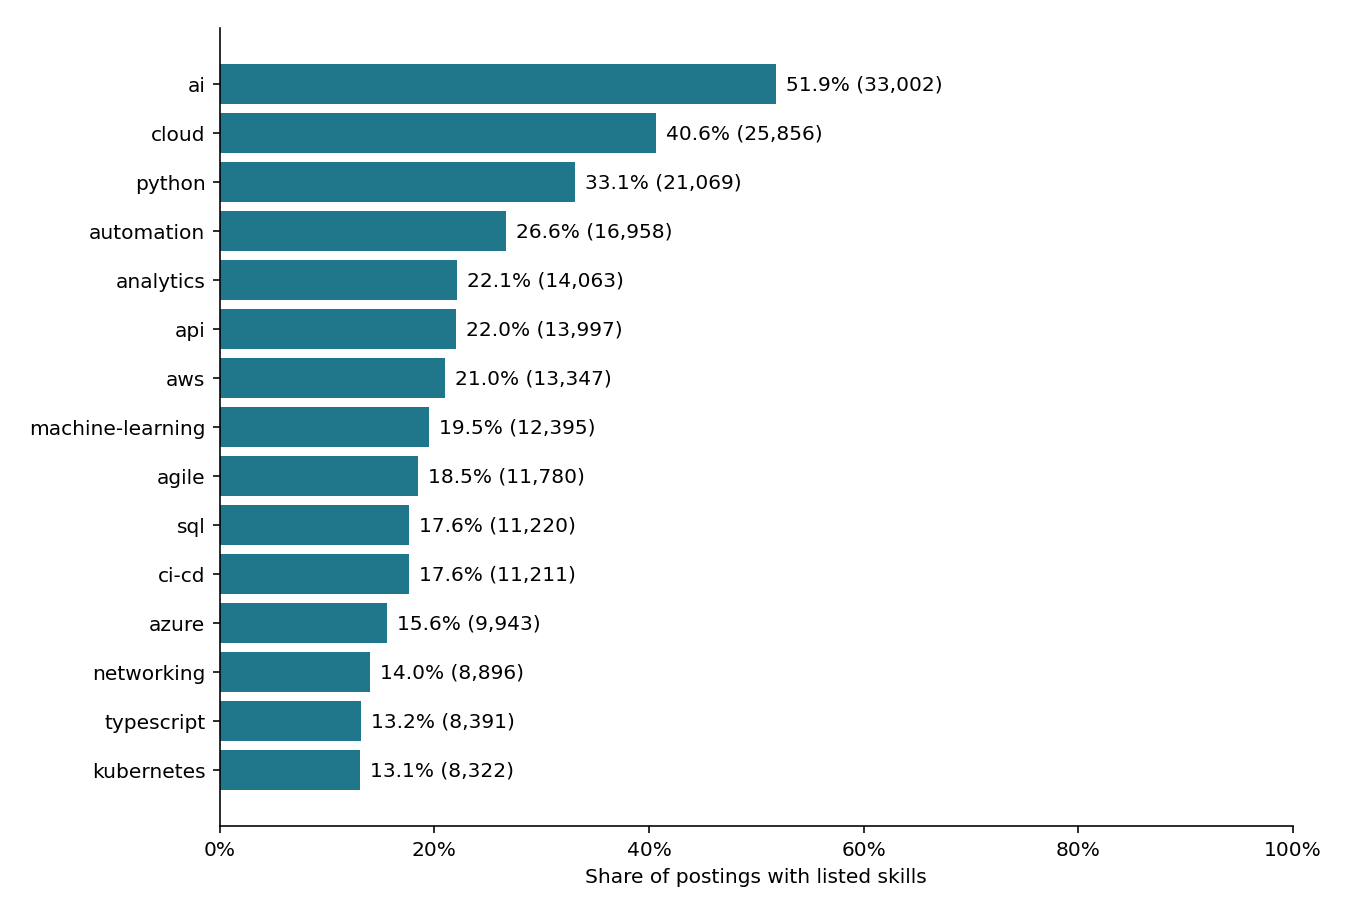

In [32]:
def plot_skill_frequency(counts, denominator, height):
    shares = counts / denominator
    fig, ax = plt.subplots(figsize=(9, height), layout="constrained")
    positions = np.arange(len(shares))
    bars = ax.barh(positions, shares, color="#20768a")
    ax.bar_label(bars, labels=[f"{share:.1%} ({count:,})" for share, count in zip(shares, counts)],
                 padding=5)
    ax.set_yticks(positions, shares.index)
    ax.invert_yaxis()
    ax.set(xlabel="Share of postings with listed skills", xlim=(0, 1))
    ax.xaxis.set_major_formatter(ticker.PercentFormatter(1))
    ax.spines[["top", "right"]].set_visible(False)
    show_figure(fig)

plot_skill_frequency(tag_counts.head(15), len(skill_postings), height=6)

**Finding.** The three most common recorded tags are `ai` (33,002 postings), `cloud` (25,856), and `python` (21,069). These counts describe the dataset's skill tags. A posting can list several skills, and missing skill lists are outside the denominator.

### How often each of the nine skill groups appears

A posting counts once for a group if it lists any skill assigned to that group. It can count toward several groups, so the percentages can sum to more than 100%. The labels show two example tags from each group.

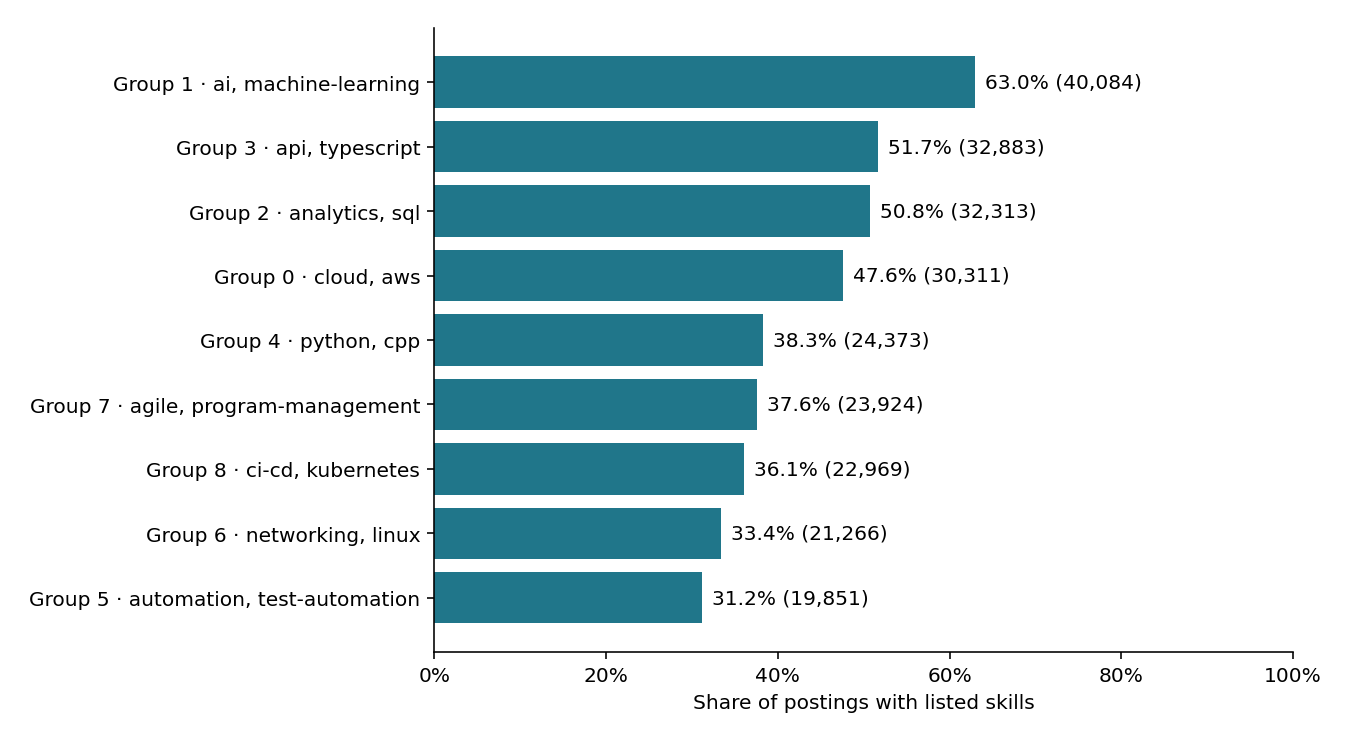

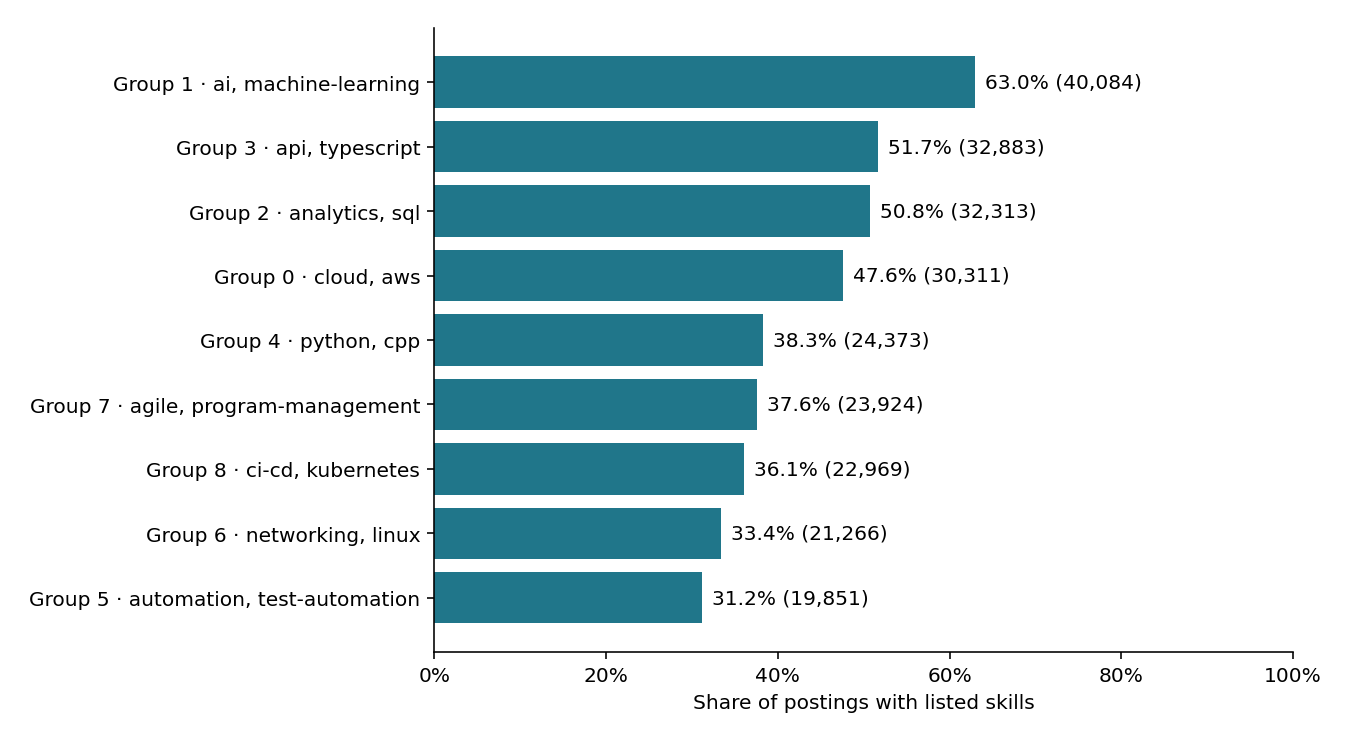

In [33]:
group_counts = skill_postings[skill_cols].sum().sort_values(ascending=False)
group_counts.index = [
    f"Group {group} · {', '.join(clusters[group][:2])}"
    for group in (int(column.rsplit("_", 1)[1]) for column in group_counts.index)
]
plot_skill_frequency(group_counts, len(skill_postings), height=4.8)

**Finding.** Group 1 is the most common (63.0%), followed by Groups 3 and 2 at roughly half of postings each. Even the least common group appears in 31.2%. Group 1 includes AI and machine learning alongside broader skills.

### Skill groups and advertised salary

Among postings with at least one listed skill, compare median salary when each skill group is mentioned and when it is absent. The table also reports sample sizes and point-biserial correlation, calculated as Pearson correlation between the binary group indicator and yearly salary.

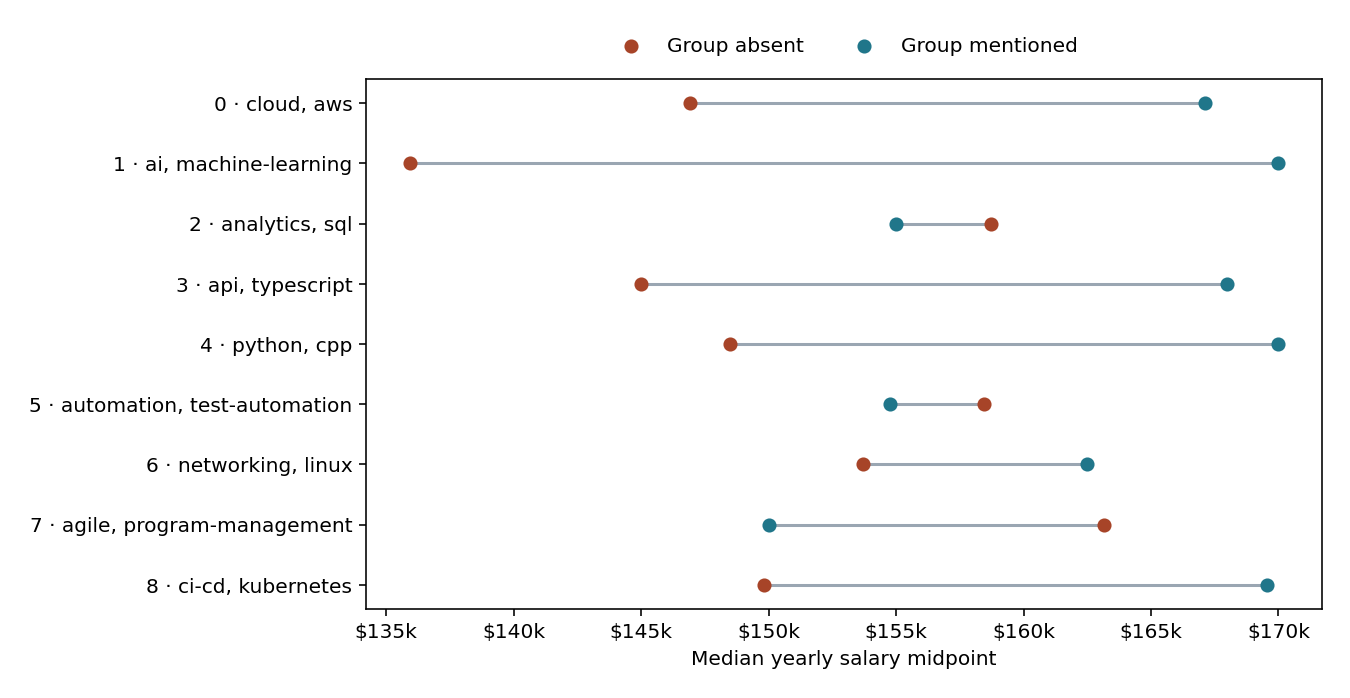

,Absent postings,Present postings,Absent median,Present median,Correlation
Skill group and examples,,,,,
"0 · cloud, aws",33328,30311,146900.0,167100.0,0.165
"1 · ai, machine-learning",23555,40084,135924.0,170000.0,0.278
"2 · analytics, sql",31326,32313,158730.0,155000.0,-0.027
"3 · api, typescript",30756,32883,145000.0,168000.0,0.175
"4 · python, cpp",39266,24373,148500.0,170000.0,0.198
"5 · automation, test-automation",43788,19851,158450.0,154750.0,-0.024
"6 · networking, linux",42373,21266,153687.0,162500.0,0.085
"7 · agile, program-management",39715,23924,163165.0,150000.0,-0.096
"8 · ci-cd, kubernetes",40670,22969,149800.0,169550.0,0.156


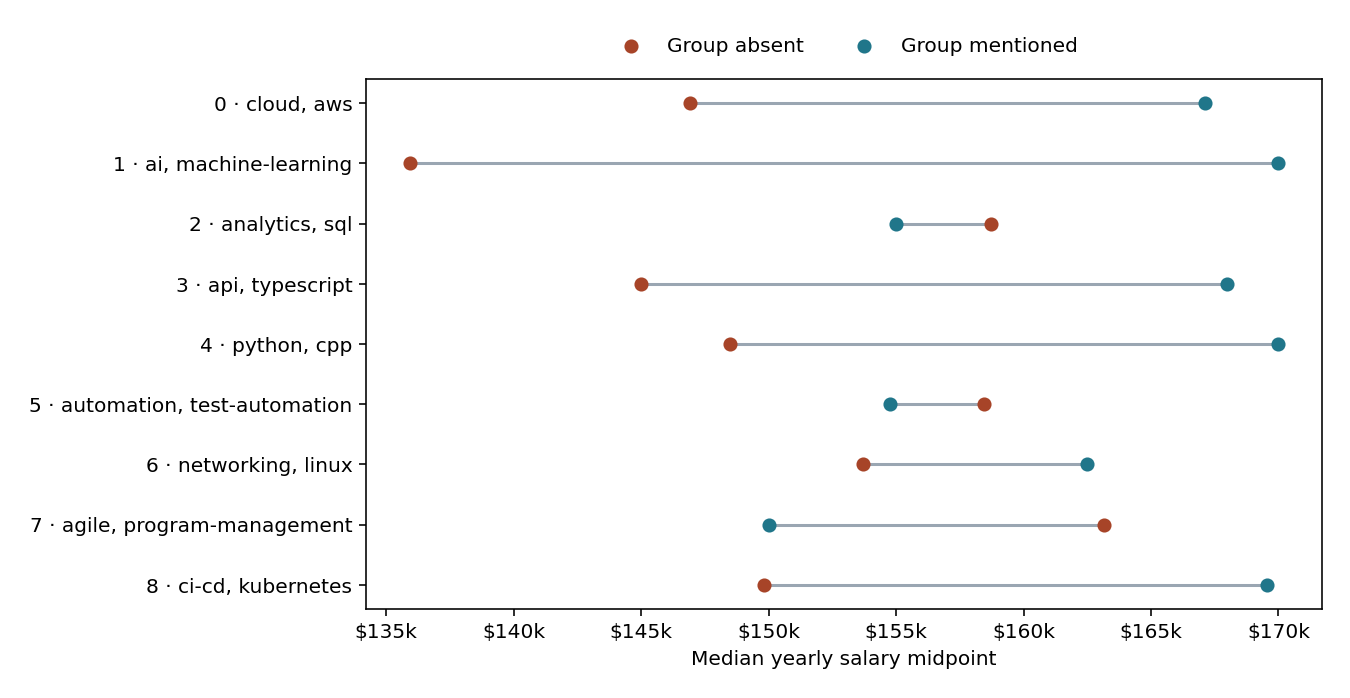

,Absent postings,Present postings,Absent median,Present median,Correlation
Skill group and examples,,,,,
"0 · cloud, aws",33328,30311,146900.0,167100.0,0.165
"1 · ai, machine-learning",23555,40084,135924.0,170000.0,0.278
"2 · analytics, sql",31326,32313,158730.0,155000.0,-0.027
"3 · api, typescript",30756,32883,145000.0,168000.0,0.175
"4 · python, cpp",39266,24373,148500.0,170000.0,0.198
"5 · automation, test-automation",43788,19851,158450.0,154750.0,-0.024
"6 · networking, linux",42373,21266,153687.0,162500.0,0.085
"7 · agile, program-management",39715,23924,163165.0,150000.0,-0.096
"8 · ci-cd, kubernetes",40670,22969,149800.0,169550.0,0.156


In [34]:
with_skills = final.loc[final["skills_listed"].eq(1)]
skill_labels = [f"{i} · {', '.join(clusters[i][:2])}" for i in range(len(skill_cols))]
skill_salary = []
for column, label in zip(skill_cols, skill_labels):
    absent = with_skills.loc[with_skills[column].eq(0), target]
    present = with_skills.loc[with_skills[column].eq(1), target]
    skill_salary.append({
        "Skill group and examples": label,
        "Absent postings": len(absent), "Present postings": len(present),
        "Absent median": absent.median(), "Present median": present.median(),
        "Correlation": with_skills[column].corr(with_skills[target]),
    })
skill_salary = pd.DataFrame(skill_salary).set_index("Skill group and examples")
positions = np.arange(len(skill_salary))
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hlines(positions, skill_salary["Absent median"], skill_salary["Present median"], color="#9aa6b2")
ax.scatter(skill_salary["Absent median"], positions, color="#a74428", label="Group absent", zorder=3)
ax.scatter(skill_salary["Present median"], positions, color="#20768a", label="Group mentioned", zorder=3)
ax.set_yticks(positions, skill_salary.index)
ax.invert_yaxis()
ax.set_xlabel("Median yearly salary midpoint")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(salary_tick))
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2)
show_figure(fig)
display(skill_salary.round({"Absent median": 0, "Present median": 0, "Correlation": 3}))

**Finding.** Group 1 has the strongest positive correlation among the nine groups in this comparison (about 0.28). Among postings that list skills, the median is $170,000 when Group 1 is mentioned and $135,924 when it is absent. Experience, company size, job function, and geography can contribute to this unadjusted difference.

## 8. Salary by minimum experience and company size

These plots show how advertised yearly salary varies with reported minimum experience and the largest reported company-size band.

### Salary by minimum-experience band

Each posting belongs to one band. The boundaries are **0 to under 5**, **5 to under 10**, and **10 through 15** years. Unlisted experience has its own box. The horizontal line inside each box is the median, and the box spans the middle 50% of salaries.

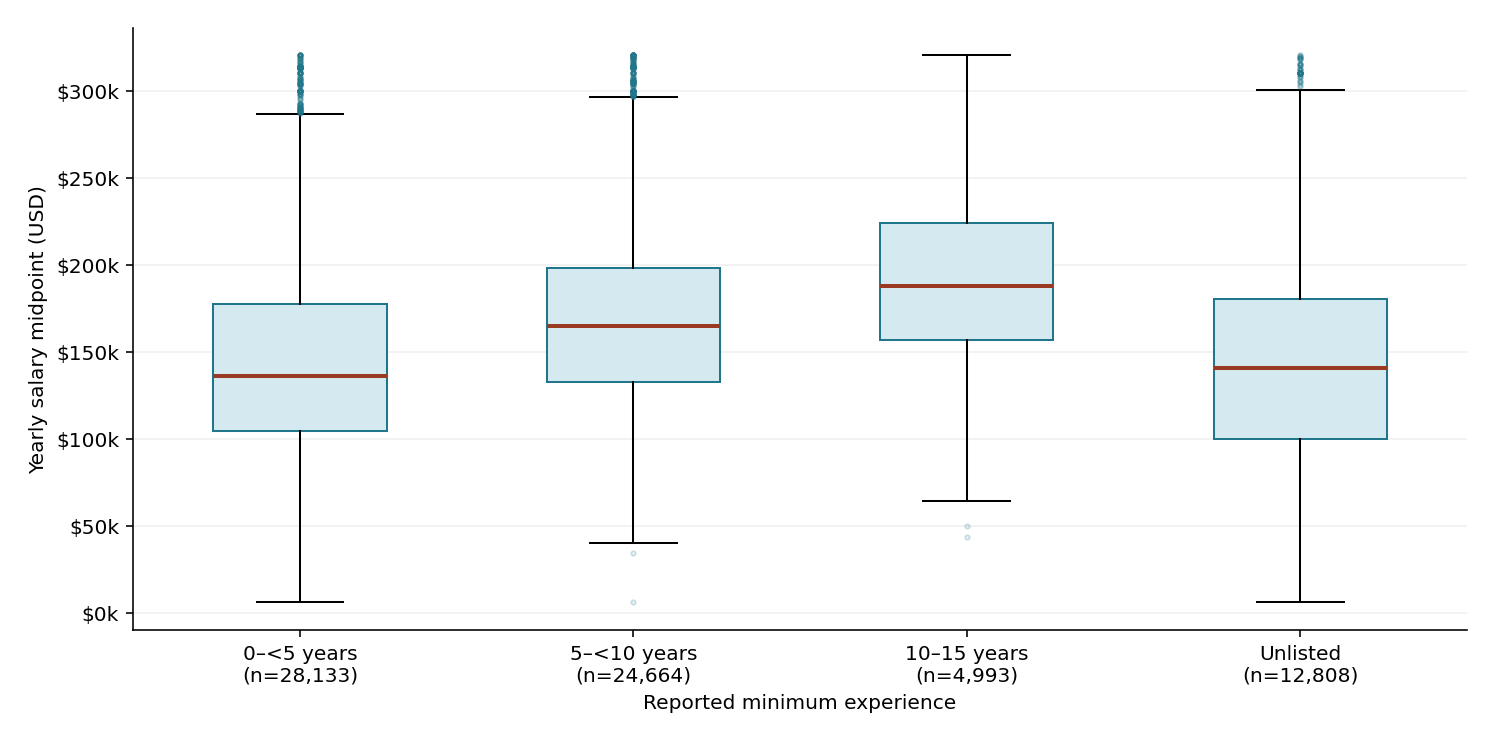

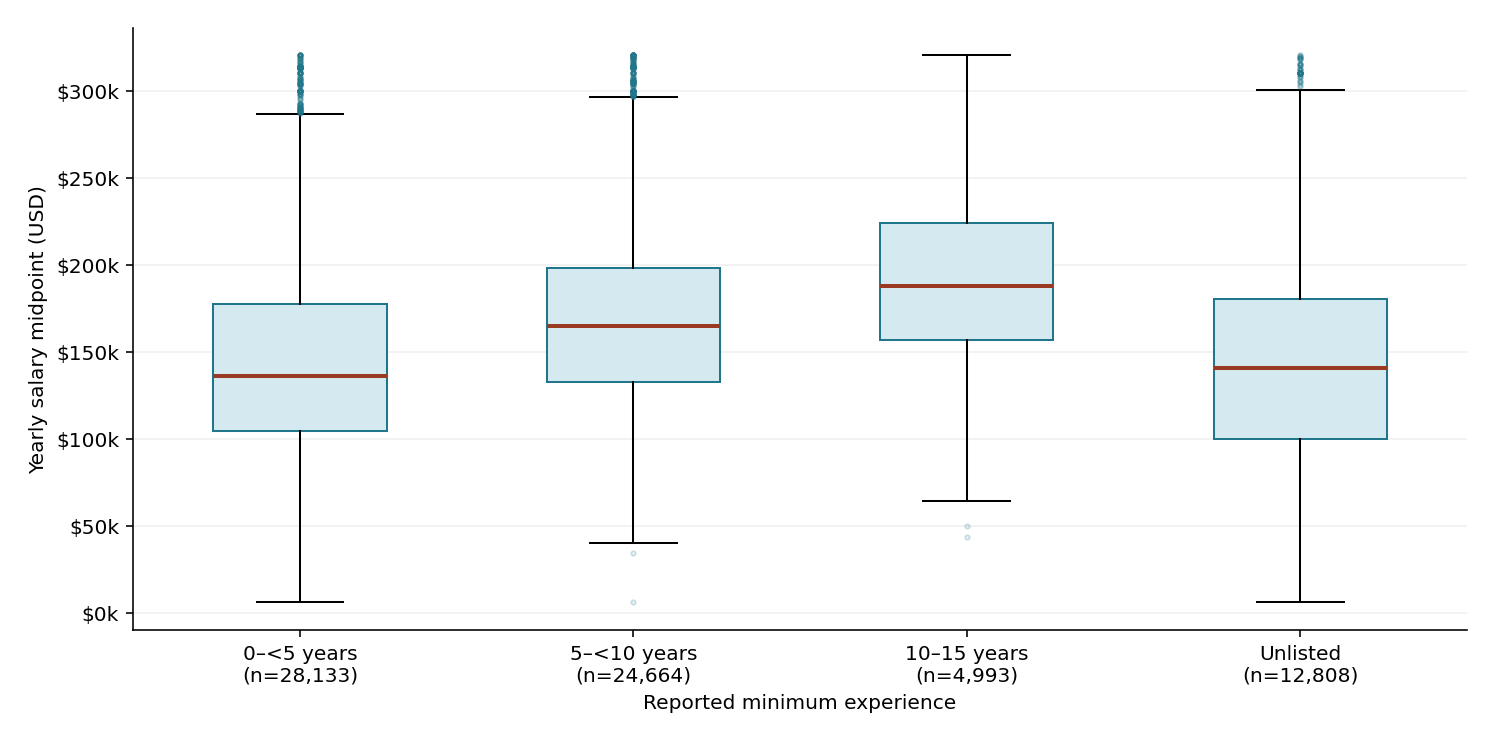

In [35]:
years = final["experience_years_min"]
experience_groups = {
    "0–<5 years": years.ge(0) & years.lt(5),
    "5–<10 years": years.ge(5) & years.lt(10),
    "10–15 years": years.between(10, 15),
    "Unlisted": years.isna(),
}
salary_by_experience = {
    label: final.loc[mask, target] for label, mask in experience_groups.items()
}
assert sum(map(len, salary_by_experience.values())) == len(final)
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
ax.boxplot(list(salary_by_experience.values()), patch_artist=True, widths=0.52,
           boxprops={"facecolor": "#d5eaf0", "edgecolor": "#20768a"},
           medianprops={"color": "#9a3a22", "linewidth": 2},
           flierprops={"markersize": 2, "alpha": 0.25, "markeredgecolor": "#20768a"})
ax.set_xticks(range(1, len(salary_by_experience) + 1), [
    f"{label}\n(n={len(salaries):,})" for label, salaries in salary_by_experience.items()
])
ax.set(xlabel="Reported minimum experience", ylabel="Yearly salary midpoint (USD)")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(salary_tick))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

**Finding.** The median rises from $136,000 in the 0 to under 5 years band to $187,750 in the 10–15 years band. Salary ranges still overlap across bands. The unlisted group remains separate from postings with a stated zero-year minimum.

### Salary by largest reported company-size band

Each posting contributes to one band. If it lists several bands, the chart uses the largest one. **Unlisted** combines blank and empty size lists. The dot is the median, and the vertical line spans the middle 50% of salaries. Counts below each band show how many postings it contains.

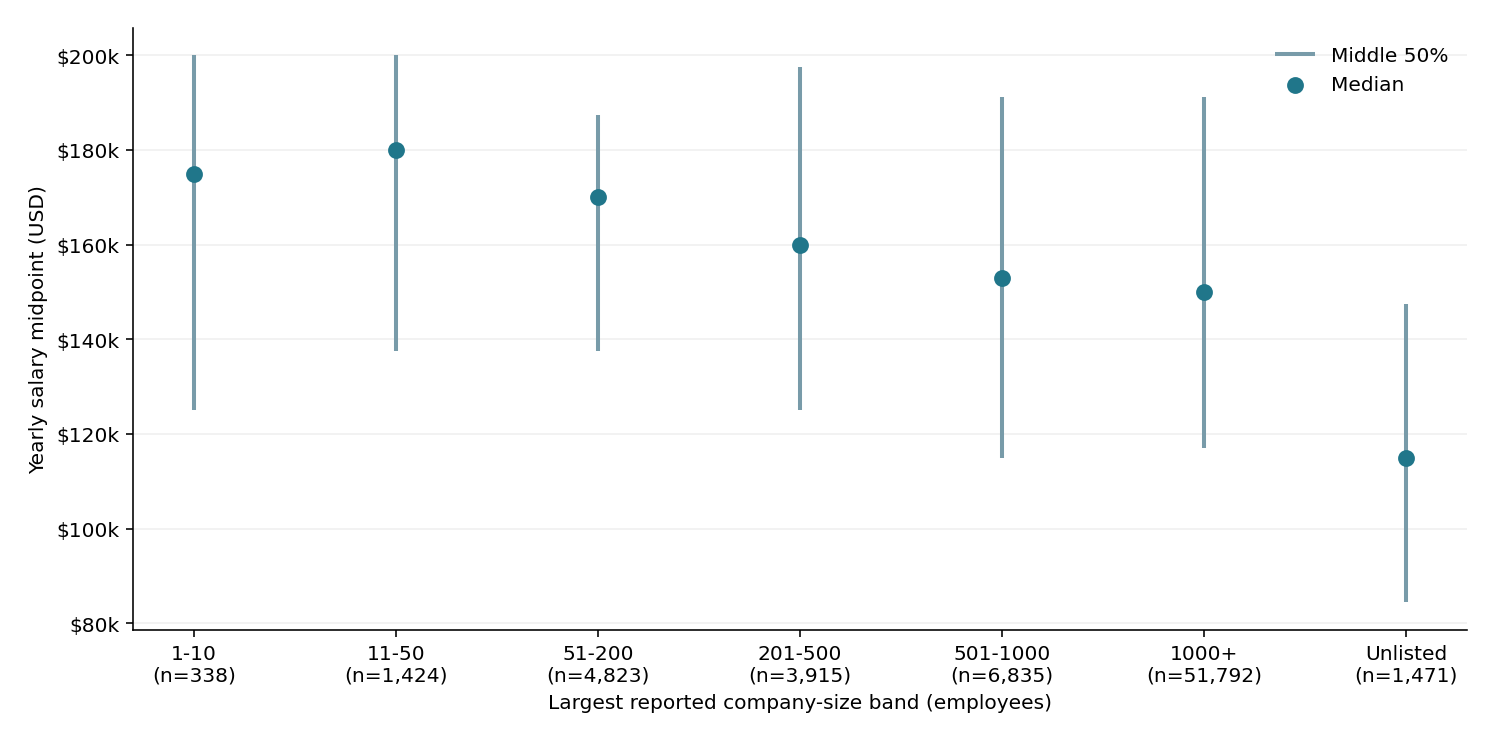

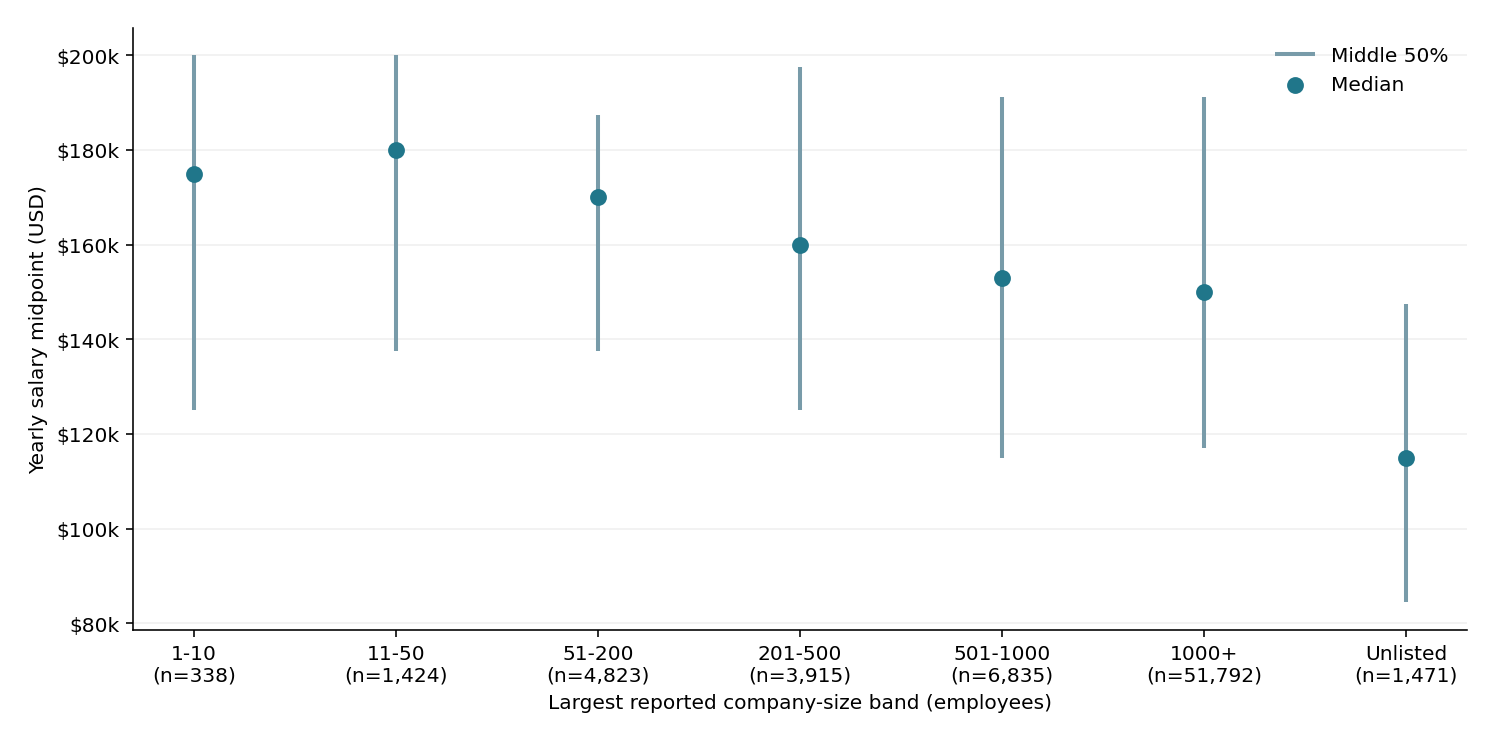

In [36]:
salary_by_company_size = {
    band: final.loc[final["company_size_band"].eq(band), target]
    for band in company_size_order + ["Unlisted"]
}
assert sum(map(len, salary_by_company_size.values())) == len(final)

size_summary = pd.DataFrame({
    band: salaries.quantile([0.25, 0.5, 0.75])
    for band, salaries in salary_by_company_size.items()
}).T
positions = np.arange(len(size_summary))
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
ax.vlines(positions, size_summary[0.25], size_summary[0.75],
          color="#789ba9", linewidth=2, label="Middle 50%")
ax.scatter(positions, size_summary[0.5], color="#20768a", s=54, label="Median", zorder=3)
ax.set_xticks(positions, [
    f"{band}\n(n={len(salaries):,})" for band, salaries in salary_by_company_size.items()
])
ax.legend(frameon=False, loc="upper right")
ax.set(xlabel="Largest reported company-size band (employees)",
       ylabel="Yearly salary midpoint (USD)")
ax.yaxis.set_major_formatter(ticker.FuncFormatter(salary_tick))
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
show_figure(fig)

**Finding.** The median is $150,000 for the 51,792 postings assigned to `1000+`. It is $175,000 for the 338 postings assigned to `1-10`. The largest-band rule moves postings with multiple tags out of the smaller groups, so the chart describes the remaining mix of roles in each band.

## 9. Linear regression model comparison

Fit three ordinary least squares models using the cleaned yearly USD postings in `final`, the same dataset exported to CSV. All three predict `salary_mid_year` in dollars using the same seeded 80/20 posting-level split.

| Model | Inputs before encoding |
|---|---|
| Baseline | Minimum experience, job category, seniority, work mode, employment type, largest company-size band, and `skills_listed` |
| Baseline + cost of living | Minimum experience, job category, seniority, work mode, employment type, largest company-size band, `skills_listed`, and `col_index` |
| Baseline + cost of living + skill groups | Baseline inputs, MERIC index and its missingness indicator, plus `skill_category_0` through `skill_category_8` |

All three models use the largest reported company-size band. The cost-of-living models also use MERIC’s overall index. Missing numeric values are filled with training-set medians. A binary indicator identifies postings with no matched MERIC index. The exported index stays blank for those postings. Missing categorical labels use `Unknown`, and one-hot encoding uses the levels observed in training with one reference level per field. A test-only label falls back to that field's reference encoding.

In [37]:
model_numeric = ["experience_years_min", "col_index"]
model_categorical = ["category", "seniority", "work_mode", "employment_type", "company_size_band"]
model_binary = ["skills_listed"]
model_data = final[[target] + model_numeric + model_categorical + model_binary + skill_cols]

shuffled_rows = np.random.RandomState(42).permutation(len(model_data))
test_count = int(np.ceil(0.20 * len(model_data)))
test_model = model_data.iloc[shuffled_rows[:test_count]]
train_model = model_data.iloc[shuffled_rows[test_count:]]

def make_baseline_inputs(train_model, test_model):
    train_medians = train_model[model_numeric].median()
    train_numbers = train_model[model_numeric].fillna(train_medians)
    test_numbers = test_model[model_numeric].fillna(train_medians)
    train_numbers = train_numbers.assign(col_index_missing=train_model["col_index"].isna().astype(int))
    test_numbers = test_numbers.assign(col_index_missing=test_model["col_index"].isna().astype(int))

    train_labels = train_model[model_categorical].fillna("Unknown")
    test_labels = test_model[model_categorical].fillna("Unknown")
    train_categories = pd.get_dummies(train_labels, drop_first=True, dtype=float)
    test_categories = pd.get_dummies(test_labels, dtype=float).reindex(
        columns=train_categories.columns, fill_value=0
    )
    train_base = pd.concat([train_numbers, train_categories, train_model[model_binary]], axis=1)
    test_base = pd.concat([test_numbers, test_categories, test_model[model_binary]], axis=1)
    return train_base, test_base


train_base, test_base = make_baseline_inputs(train_model, test_model)

train_y = train_model[target].to_numpy()
test_y = test_model[target].to_numpy()

def fit_ols(train_features, test_features, outcome):
    train_design = np.column_stack([np.ones(len(train_features)), train_features.to_numpy(dtype=float)])
    test_design = np.column_stack([np.ones(len(test_features)), test_features.to_numpy(dtype=float)])
    coefficients = np.linalg.lstsq(train_design, outcome, rcond=None)[0]
    predicted = np.einsum("ij,j->i", test_design, coefficients)
    assert np.isfinite(predicted).all()
    return coefficients, predicted


no_col_features = train_base.columns.difference(["col_index", "col_index_missing"], sort=False)
baseline_coefficients, baseline_predictions = fit_ols(train_base[no_col_features], test_base[no_col_features], train_y)
_, col_predictions = fit_ols(train_base, test_base, train_y)
train_with_skills = train_base.join(train_model[skill_cols])
test_with_skills = test_base.join(test_model[skill_cols])
skill_coefficients, skill_predictions = fit_ols(train_with_skills, test_with_skills, train_y)
predictions = {
    "Baseline": baseline_predictions,
    "Baseline + cost of living": col_predictions,
    "Baseline + cost of living + skill groups": skill_predictions,
}
test_total_variation = np.square(test_y - test_y.mean()).sum()
model_results = []
for name, predicted in predictions.items():
    errors = test_y - predicted
    model_results.append({
        "Model": name,
        "MAE (USD)": np.abs(errors).mean(),
        "RMSE (USD)": np.sqrt(np.square(errors).mean()),
        "R²": 1 - np.square(errors).sum() / test_total_variation,
    })
model_results = pd.DataFrame(model_results).set_index("Model")
print(f"Training postings: {len(train_model):,} | Test postings: {len(test_model):,}")
display(model_results.round({"MAE (USD)": 2, "RMSE (USD)": 2, "R²": 3}))

Training postings: 56,478 | Test postings: 14,120


,MAE (USD),RMSE (USD),R²
Model,,,
Baseline,31574.44,40542.21,0.401
Baseline + cost of living,30899.60,39757.11,0.424
Baseline + cost of living + skill groups,30015.18,38921.70,0.448


Training postings: 56,478 | Test postings: 14,120


,MAE (USD),RMSE (USD),R²
Model,,,
Baseline,31574.44,40542.21,0.401
Baseline + cost of living,30899.60,39757.11,0.424
Baseline + cost of living + skill groups,30015.18,38921.70,0.448


### How to read the test metrics

- **MAE (USD)** is the average absolute dollar difference between predicted and advertised salary. Lower is better.
- **RMSE (USD)** squares each error before averaging and then takes the square root. Large misses receive more weight, so this metric is useful when large errors matter. Lower is better.
- **R²** measures how much lower the sum of squared errors is compared with predicting the test-set mean for every posting. An R² of 0.424 corresponds to a 42.4% reduction in squared error relative to that reference. Higher is better. A negative value means worse performance than that reference.

**Finding.** Adding the MERIC index and its missingness indicator to the baseline lowered test MAE by about $675, from $31,574 to $30,900. Adding all nine skill indicators reduced MAE by a further $884 to $30,015. All three models were evaluated on the same postings.

### Baseline regression coefficients

Coefficients are changes in predicted yearly salary in USD, holding the other encoded inputs fixed. The experience coefficient is per additional year. Each categorical coefficient is relative to its field's listed reference level. These estimates describe associations in this model.

In [38]:
baseline_terms = pd.Series(baseline_coefficients, index=["Intercept", *no_col_features],
                           name="Coefficient (USD)")
reference_levels = train_model[model_categorical].fillna("Unknown").apply(
    lambda values: values.astype("category").cat.categories[0]
).rename("Reference level")
display(reference_levels.to_frame())
with pd.option_context("display.max_rows", None):
    display(baseline_terms.round(2).to_frame())

,Reference level
category,Unknown
seniority,Unknown
work_mode,Unknown
employment_type,Unknown
company_size_band,1-10


,Coefficient (USD)
Intercept,135373.86
experience_years_min,3692.98
category_ai_engineering,16305.78
category_architecture,2740.20
category_backend,2950.42
category_blockchain,-7617.75
category_business_analysis,-44236.33
category_data_analytics,-45799.78
category_data_engineering,-8991.58
category_data_science,2892.24


,Reference level
category,Unknown
seniority,Unknown
work_mode,Unknown
employment_type,Unknown
company_size_band,1-10


,Coefficient (USD)
Intercept,135373.86
experience_years_min,3692.98
category_ai_engineering,16305.78
category_architecture,2740.20
category_backend,2950.42
category_blockchain,-7617.75
category_business_analysis,-44236.33
category_data_analytics,-45799.78
category_data_engineering,-8991.58
category_data_science,2892.24


### Skill-group regression coefficients

The table shows the nine coefficients from the model with cost of living and all nine skill indicators. Each estimate is the modeled difference in yearly salary midpoint between postings with and without a mention of that group, holding the other features fixed. The coefficients describe conditional associations in advertised pay.

In [39]:
skill_terms = pd.Series(
    skill_coefficients, index=["Intercept", *train_with_skills.columns],
    name="Coefficient (USD)",
)
skill_coefficient_table = skill_terms.loc[skill_cols].to_frame().rename_axis("Skill indicator")
skill_coefficient_table.insert(0, "Example tags", [", ".join(clusters[i][:2]) for i in range(len(skill_cols))])
display(skill_coefficient_table.round(2))

,Example tags,Coefficient (USD)
Skill indicator,,
skill_category_0,"cloud, aws",2167.41
skill_category_1,"ai, machine-learning",13229.14
skill_category_2,"analytics, sql",-3606.76
skill_category_3,"api, typescript",3374.94
skill_category_4,"python, cpp",8092.84
skill_category_5,"automation, test-automation",-4455.78
skill_category_6,"networking, linux",4399.77
skill_category_7,"agile, program-management",-7857.74
skill_category_8,"ci-cd, kubernetes",1317.25


,Example tags,Coefficient (USD)
Skill indicator,,
skill_category_0,"cloud, aws",2167.41
skill_category_1,"ai, machine-learning",13229.14
skill_category_2,"analytics, sql",-3606.76
skill_category_3,"api, typescript",3374.94
skill_category_4,"python, cpp",8092.84
skill_category_5,"automation, test-automation",-4455.78
skill_category_6,"networking, linux",4399.77
skill_category_7,"agile, program-management",-7857.74
skill_category_8,"ci-cd, kubernetes",1317.25


### NMF skill-group contribution

Use the same five shuffled folds within the training partition for every feature set. Fit the imputers and categorical encoder on each fold's training rows and calculate mean validation RMSE across folds. The held-out test set is reserved for the comparison above.

- **Add one:** Compare the baseline plus cost of living with that model plus each group. A positive RMSE improvement means the group reduced prediction error.
- **Drop one:** Compare the model with cost of living and all nine groups with the model excluding one group. A positive RMSE increase means prediction error increased when that group was removed.

These comparisons measure predictive contribution. A group can help with prediction even when its association with salary varies across postings.

In [40]:
folds = np.array_split(np.random.RandomState(42).permutation(len(train_model)), 5)
group_labels = [f"Group {i} ({', '.join(clusters[i][:2])})" for i in range(len(skill_cols))]
feature_sets = {
    ("benchmark", "Baseline"): [],
    ("benchmark", "All nine groups"): skill_cols,
    **{("add", label): [column] for label, column in zip(group_labels, skill_cols)},
    **{("drop", label): [c for c in skill_cols if c != column]
       for label, column in zip(group_labels, skill_cols)},
}
fold_rmse = {key: [] for key in feature_sets}

for valid_rows in folds:
    fit_rows = np.ones(len(train_model), dtype=bool)
    fit_rows[valid_rows] = False
    fold_train = train_model.iloc[fit_rows]
    fold_valid = train_model.iloc[valid_rows]
    fold_train_base, fold_valid_base = make_baseline_inputs(fold_train, fold_valid)
    fold_train_all = fold_train_base.join(fold_train[skill_cols])
    fold_valid_all = fold_valid_base.join(fold_valid[skill_cols])
    fold_outcome = fold_train[target].to_numpy()
    fold_actual = fold_valid[target].to_numpy()
    for key, extra in feature_sets.items():
        columns = fold_train_base.columns.tolist() + extra
        _, predicted = fit_ols(fold_train_all[columns], fold_valid_all[columns], fold_outcome)
        fold_rmse[key].append(np.sqrt(np.square(fold_actual - predicted).mean()))

cv_rmse = {key: np.mean(scores) for key, scores in fold_rmse.items()}
baseline_rmse = cv_rmse[("benchmark", "Baseline")]
full_skill_rmse = cv_rmse[("benchmark", "All nine groups")]
display(pd.Series({"Baseline + cost of living": baseline_rmse, "Baseline + cost of living + all nine groups": full_skill_rmse},
                  name="Mean CV RMSE (USD)").round(2).to_frame())

nmf_contribution = pd.DataFrame({
    "Add one: CV RMSE (USD)": [cv_rmse[("add", label)] for label in group_labels],
    "Add one: RMSE improvement (USD)": [baseline_rmse - cv_rmse[("add", label)] for label in group_labels],
    "Drop one: CV RMSE (USD)": [cv_rmse[("drop", label)] for label in group_labels],
    "Drop one: RMSE increase (USD)": [cv_rmse[("drop", label)] - full_skill_rmse for label in group_labels],
}, index=pd.Index(group_labels, name="Skill group"))
display(nmf_contribution.round(2))

,Mean CV RMSE (USD)
Baseline + cost of living,39459.51
Baseline + cost of living + all nine groups,38581.60


,Add one: CV RMSE (USD),Add one: RMSE improvement (USD),Drop one: CV RMSE (USD),Drop one: RMSE increase (USD)
Skill group,,,,
"Group 0 (cloud, aws)",39415.29,44.23,38589.87,8.28
"Group 1 (ai, machine-learning)",39023.96,435.56,38961.29,379.69
"Group 2 (analytics, sql)",39439.86,19.65,38612.00,30.40
"Group 3 (api, typescript)",39410.28,49.23,38604.66,23.06
"Group 4 (python, cpp)",39279.30,180.21,38702.17,120.57
"Group 5 (automation, test-automation)",39444.78,14.73,38624.40,42.80
"Group 6 (networking, linux)",39397.60,61.91,38617.47,35.87
"Group 7 (agile, program-management)",39311.64,147.87,38725.22,143.62
"Group 8 (ci-cd, kubernetes)",39447.84,11.67,38583.31,1.71


,Mean CV RMSE (USD)
Baseline + cost of living,39459.51
Baseline + cost of living + all nine groups,38581.60


,Add one: CV RMSE (USD),Add one: RMSE improvement (USD),Drop one: CV RMSE (USD),Drop one: RMSE increase (USD)
Skill group,,,,
"Group 0 (cloud, aws)",39415.29,44.23,38589.87,8.28
"Group 1 (ai, machine-learning)",39023.96,435.56,38961.29,379.69
"Group 2 (analytics, sql)",39439.86,19.65,38612.00,30.40
"Group 3 (api, typescript)",39410.28,49.23,38604.66,23.06
"Group 4 (python, cpp)",39279.30,180.21,38702.17,120.57
"Group 5 (automation, test-automation)",39444.78,14.73,38624.40,42.80
"Group 6 (networking, linux)",39397.60,61.91,38617.47,35.87
"Group 7 (agile, program-management)",39311.64,147.87,38725.22,143.62
"Group 8 (ci-cd, kubernetes)",39447.84,11.67,38583.31,1.71


**Finding.** Group 1 (AI and machine learning) showed the largest improvement in the add-one comparison, reducing mean validation RMSE by about $436. It also had the largest drop-one effect: removing Group 1 from the full model increased mean RMSE by about $380. The full set of nine groups reduced mean validation RMSE by about $878 relative to the baseline plus cost of living.